# Comparing structural features to confidence scores

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import statsmodels.api as sm

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
entries = pd.read_csv('../data/interim/sequences_sample.csv')

In [4]:
entries['type'] = entries['label'].map(lambda label: 'binder' if label else 'decoy')

In [5]:
confidence_scores = pd.read_csv('../data/processed/af3_confidence_scores.csv')
af3_structural_features = pd.read_csv('../data/processed/af3_structural_features.csv')

structure_scores = entries.merge(
    confidence_scores,
    how='left',
    left_on='index',
    right_on='structure_name',
).merge(
    af3_structural_features,
    how='inner',
    left_on=['index', 'sample', 'seed'],
    right_on=['name', 'sample', 'seed'],
)

In [6]:
structural_features = pd.read_csv('../data/processed/tcr_pmhc_structural_features_temp.csv')

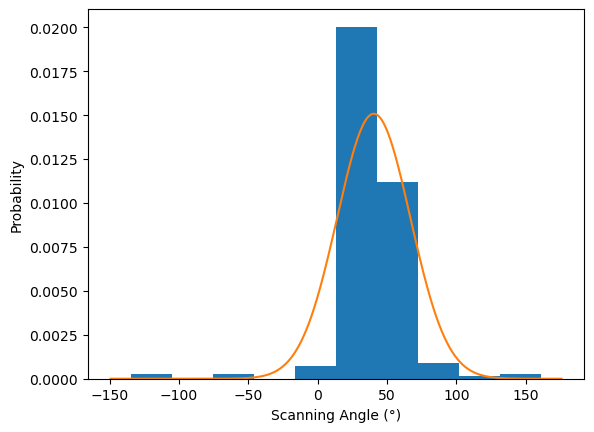

In [7]:
loc, scale = scipy.stats.norm.fit(structural_features['scanning_angle'])
scanning_angle = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['scanning_angle'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = scanning_angle.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Scanning Angle (°)')
plt.ylabel('Probability')

plt.show()

In [8]:
structure_scores['scanning_angle_probability'] = structure_scores['scanning_angle'].apply(scanning_angle.pdf)

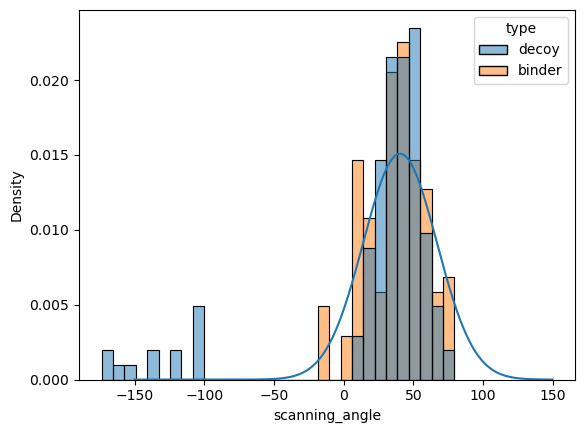

In [9]:
x = np.linspace(-150, 150, 1000)
plt.plot(x, scanning_angle.pdf(x))

sns.histplot(structure_scores, hue='type', x='scanning_angle', stat='density', common_norm=False)

plt.show()

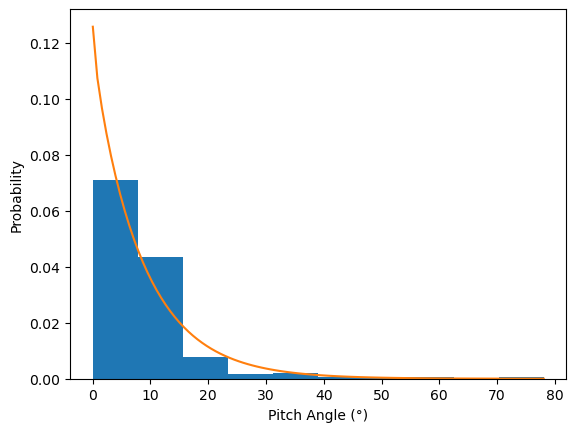

In [10]:
a, loc, scale = scipy.stats.gamma.fit(structural_features['pitch_angle'], floc=0)
pitch_angle = scipy.stats.gamma(a=a, loc=loc, scale=scale)

ax = structural_features['pitch_angle'].plot.hist(density=True)

x = np.linspace(structural_features['pitch_angle'].min(), structural_features['pitch_angle'].max(), 100)
y = pitch_angle.pdf(x)

plt.plot(x, y, '-')


plt.xlabel('Pitch Angle (°)')
plt.ylabel('Probability')

plt.show()

In [11]:
structure_scores['pitch_angle_probability'] = structure_scores['pitch_angle'].apply(pitch_angle.pdf)

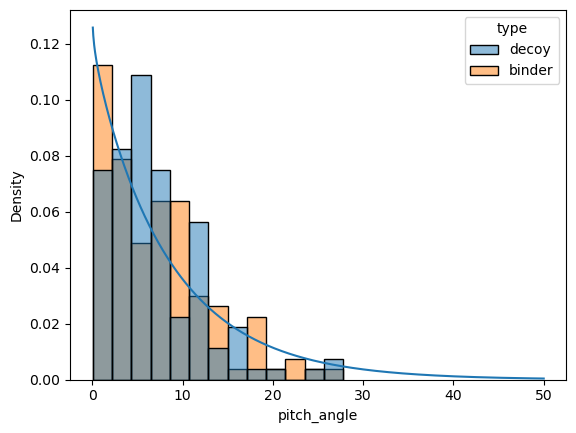

In [12]:
x = np.linspace(0, 50, 1000)
plt.plot(x, pitch_angle.pdf(x))

sns.histplot(structure_scores, x='pitch_angle', hue='type', stat='density', common_norm=False)

plt.show()

In [13]:
def z_score(x: float | np.ndarray, means: np.ndarray, variances: np.ndarray, weights: np.ndarray) -> float | np.ndarray:
    pdfs = [
        w * scipy.stats.norm.pdf(x, loc=mu, scale=np.sqrt(var))
        for w, mu, var in zip(weights, means, variances, strict=True)
    ]

    return np.sum(pdfs, axis=0)

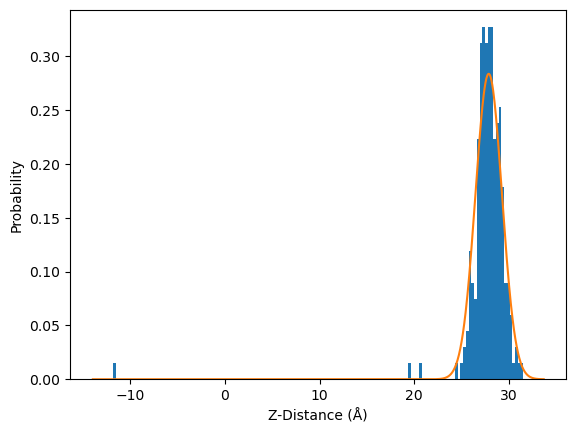

In [14]:
gmm = sklearn.mixture.GaussianMixture(n_components=2)
gmm.fit(structural_features['z_score'].to_numpy().reshape(-1, 1))

ax = structural_features['z_score'].plot.hist(bins=150, density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = z_score(x, gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten())

plt.plot(x, y, '-')

plt.xlabel('Z-Distance (Å)')
plt.ylabel('Probability')

plt.show()

In [15]:
structure_scores['z_score_probability'] = structure_scores['z_score'].apply(
    z_score, means=gmm.means_.flatten(), variances=gmm.covariances_.flatten(), weights=gmm.weights_.flatten()
)

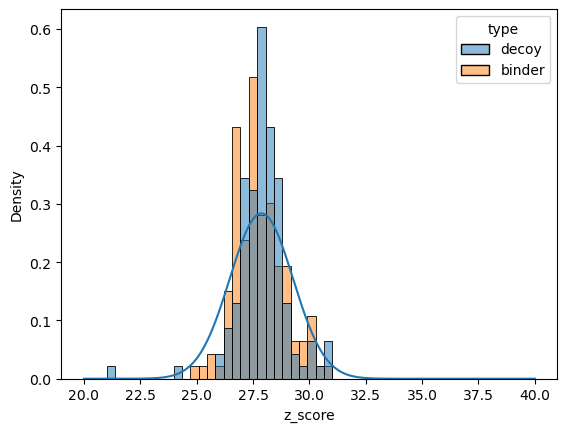

In [16]:
x = np.linspace(20, 40, 1000)
plt.plot(x, z_score(x, gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten()))

sns.histplot(structure_scores, x='z_score', hue='type', stat='density', common_norm=False)

plt.show()

In [17]:
contact_probabilities = pd.read_csv('../data/external/tcr_pmhc_contacts.csv')

contact_probabilities['proportion'] = contact_probabilities.groupby('mhc_type')['proportion'].transform(
    lambda group: group / group.sum()
)

contact_maps = pd.read_csv('../data/processed/af3_contact_maps.csv')

contact_scores = (
    contact_maps.merge(
        contact_probabilities,
        how='left',
        on=[col for col in contact_probabilities if col != 'proportion'],
    )
    .groupby(['name', 'seed', 'sample'])['proportion']
    .aggregate(['sum', 'mean'])
)
contact_scores.columns = ['contact_map_probability_' + column_name for column_name in contact_scores.columns]

structure_scores = structure_scores.merge(
    contact_scores, how='left', left_on=['name', 'seed', 'sample'], right_index=True
)

<Axes: xlabel='score', ylabel='probability'>

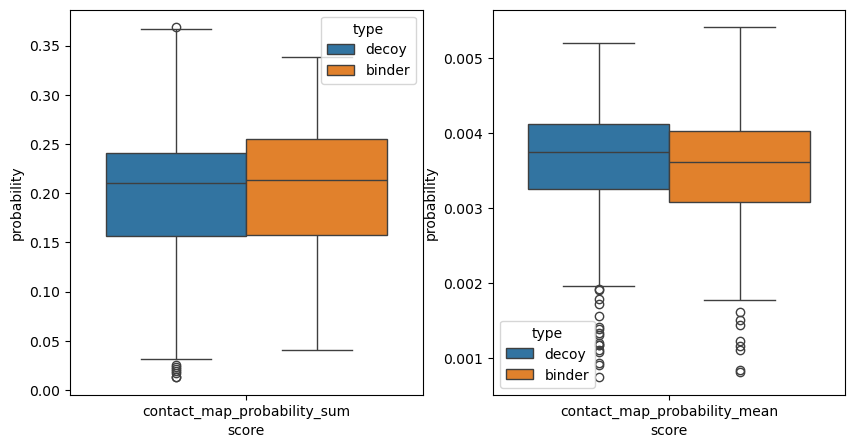

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_sum',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[0],
)

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_mean',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[1],
)

In [19]:
structure_scores['contact_map_probability'] = structure_scores['contact_map_probability_mean']

In [20]:
interactions = pd.read_csv('../data/processed/tcr_pmhc_interactions_temp.csv')

In [21]:
num_interactions = interactions.groupby('name').size()

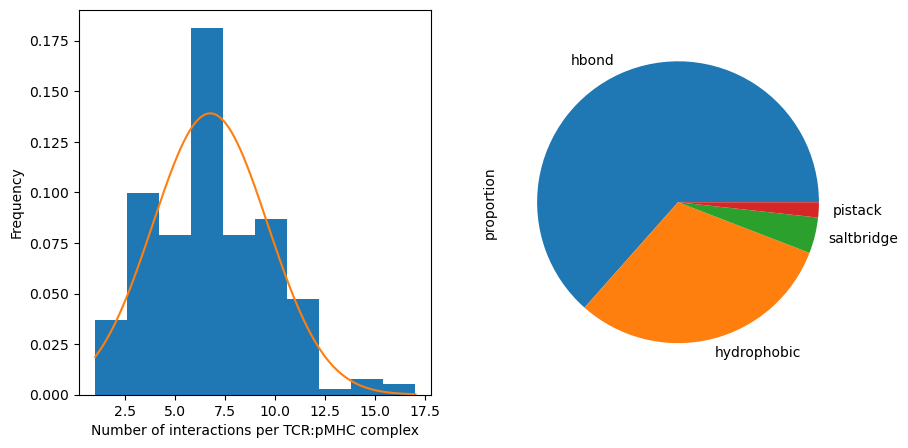

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

num_interactions.plot.hist(ax=axes[0], density=True)
x = np.linspace(num_interactions.min(), num_interactions.max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=num_interactions.std())

axes[0].plot(x, y, '-')

axes[0].set_xlabel('Number of interactions per TCR:pMHC complex')

interactions.value_counts('type', normalize=True).plot.pie(ax=axes[1])

plt.show()

In [23]:
interaction_types = interactions.value_counts(['type', 'name'])

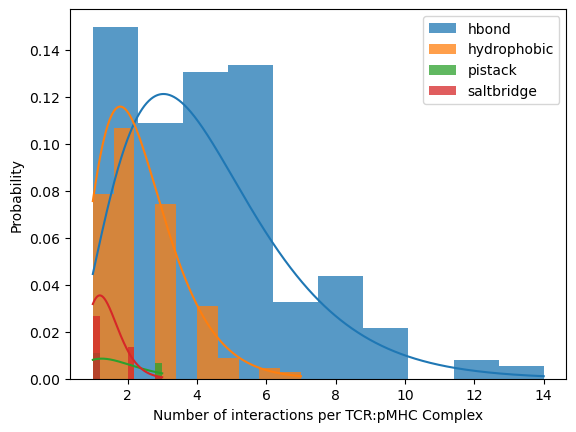

In [24]:
colours = plt.rcParams['axes.prop_cycle'].by_key()['color']

total_count = interaction_types.sum()

interaction_types_parameters = {}

for i, (interaction_type, group) in enumerate(interaction_types.reset_index().groupby('type')):
    interaction_types_parameters[interaction_type] = {}

    colour = colours[i % len(colours)]

    count = group['count']
    group_count = count.sum()

    weight = group_count / total_count

    a, loc, scale = scipy.stats.gamma.fit(group['count'], floc=0)

    interaction_types_parameters[interaction_type]['weight'] = weight
    interaction_types_parameters[interaction_type]['a'] = a
    interaction_types_parameters[interaction_type]['loc'] = loc
    interaction_types_parameters[interaction_type]['scale'] = scale

    x = np.linspace(count.min(), count.max(), 1000)
    y = scipy.stats.gamma.pdf(x, a=a, loc=loc, scale=scale) * weight

    plt.plot(x, y, '-', color=colour)

    counts, bins = np.histogram(count)
    probabilities = (counts / counts.sum()) * weight

    plt.stairs(
        probabilities,
        bins,
        fill=True,
        color=colour,
        alpha=0.75,
        label=interaction_type,
    )

plt.legend()
plt.ylabel('Probability')
plt.xlabel('Number of interactions per TCR:pMHC Complex')
plt.show()

In [25]:
af3_interactions = pd.read_csv('../data/processed/af3_interactions.csv')
af3_interactions = af3_interactions.merge(
    entries, how='left', left_on='name', right_on='index', suffixes=('_interaction', '')
)

ROC-AUC: 0.5866610301768991


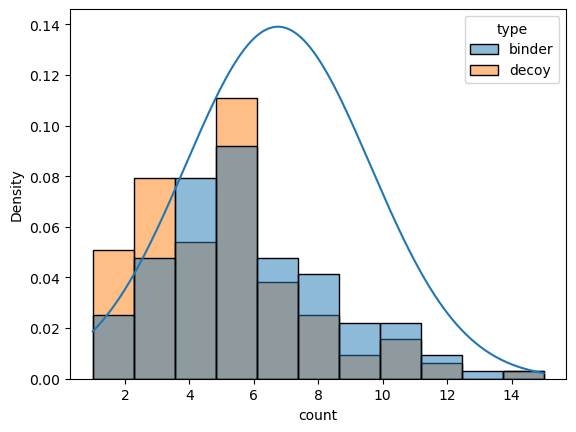

In [26]:
af3_interaction_counts = af3_interactions.groupby(['type', 'label', 'name', 'seed', 'sample']).size()
af3_interaction_counts.name = 'count'
af3_interaction_counts = af3_interaction_counts.reset_index()

sns.histplot(af3_interaction_counts, x='count', hue='type', stat='density')

x = np.linspace(af3_interaction_counts['count'].min(), af3_interaction_counts['count'].max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=num_interactions.std())
plt.plot(x, y, '-')

print('ROC-AUC:', sklearn.metrics.roc_auc_score(af3_interaction_counts['label'], af3_interaction_counts['count']))

plt.show()

In [27]:
af3_interaction_counts['num_interactions_probability'] = scipy.stats.norm.pdf(
    af3_interaction_counts['count'], loc=num_interactions.mean(), scale=num_interactions.std()
)
structure_scores = structure_scores.merge(
    af3_interaction_counts[['name', 'seed', 'sample', 'num_interactions_probability']],
    how='left',
    left_on=['name', 'seed', 'sample'],
    right_on=['name', 'seed', 'sample'],
)
structure_scores['num_interactions_probability'] = structure_scores['num_interactions_probability'].fillna(0.0)

hbond ROC-AUC: 0.5367768595041322
hydrophobic ROC-AUC: 0.5488942307692308
pistack ROC-AUC: nan
saltbridge ROC-AUC: 0.3823529411764705


/home/imm/lina4096/.local/share/mamba/envs/tcr-pmhc-predicted-structures/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


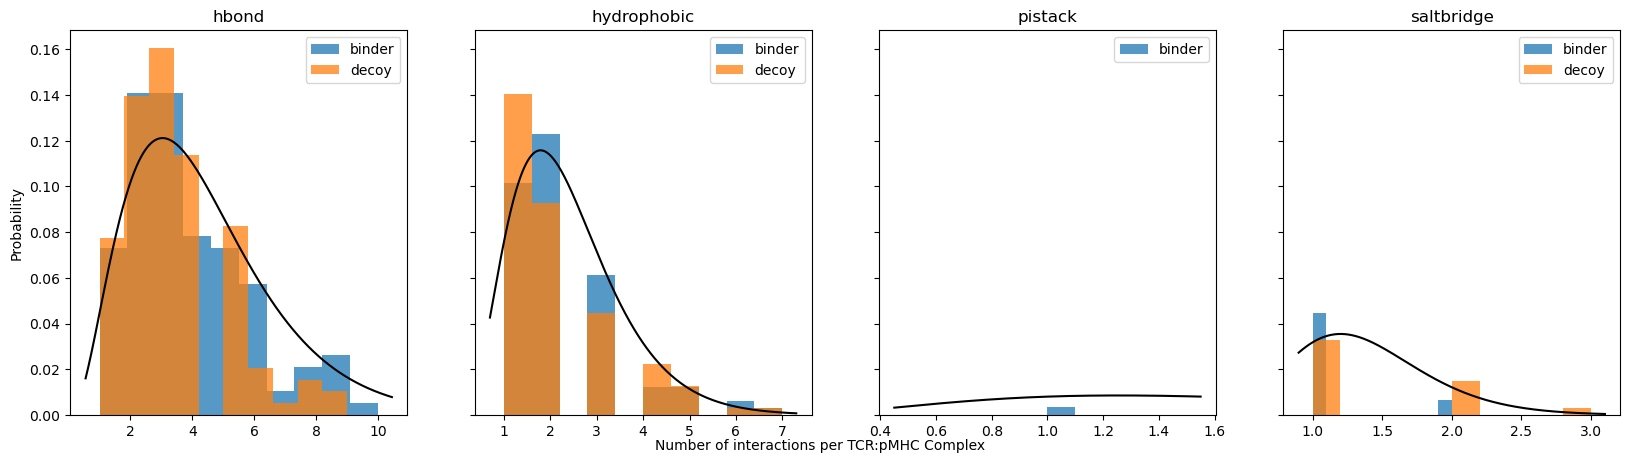

In [28]:
af3_interaction_types = af3_interactions.value_counts(
    ['name', 'seed', 'sample', 'type', 'label', 'type_interaction']
).reset_index()

total_count = af3_interaction_types['count'].sum()

number_of_interaction_types = len(interaction_types_parameters)

fig, axes = plt.subplots(1, number_of_interaction_types, figsize=(5 * number_of_interaction_types, 5), sharey=True)

for i, (interaction_type, group) in enumerate(af3_interaction_types.groupby('type_interaction')):
    group_count = group['count'].sum()

    weight = group_count / total_count

    for complex_type, sub_group in group.groupby('type'):
        counts, bins = np.histogram(sub_group['count'])
        probabilities = (counts / counts.sum()) * weight

        axes[i].stairs(
            probabilities,
            bins,
            fill=True,
            alpha=0.75,
            label=complex_type,
        )

    x = np.linspace(*axes[i].get_xlim(), 1000)
    y = (
        scipy.stats.gamma.pdf(
            x,
            a=interaction_types_parameters[interaction_type]['a'],
            loc=interaction_types_parameters[interaction_type]['loc'],
            scale=interaction_types_parameters[interaction_type]['scale'],
        )
        * interaction_types_parameters[interaction_type]['weight']
    )

    axes[i].plot(x, y, '-', color='black')

    axes[i].set_title(interaction_type)
    axes[i].legend()

    print(interaction_type, 'ROC-AUC:', sklearn.metrics.roc_auc_score(group['label'], group['count']))

axes[0].set_ylabel('Probability')
fig.text(0.5, 0.04, 'Number of interactions per TCR:pMHC Complex', ha='center')

plt.show()

In [29]:
index = pd.MultiIndex.from_frame(structure_scores[['name', 'seed', 'sample']])
probabilities = pd.Series(np.zeros(len(index)), index=index)
probabilities.name = 'interaction_type_probability'
for interaction_type, params in interaction_types_parameters.items():
    interaction_type_counts = af3_interaction_types[
        af3_interaction_types['type_interaction'] == interaction_type
    ].set_index(['name', 'seed', 'sample'])['count']

    interaction_type_probabilities = interaction_type_counts.apply(
        lambda counts, params=params: params['weight']
        * scipy.stats.gamma.pdf(counts, a=params['a'], loc=params['loc'], scale=params['scale']),
    )
    interaction_type_probabilities.name = 'interaction_type_probability'

    probabilities = probabilities.add(interaction_type_probabilities, fill_value=0.0)

structure_scores = structure_scores.merge(probabilities.reset_index(), how='left', on=['name', 'seed', 'sample'])

In [30]:
structure_probability_names = [
    'scanning_angle_probability',
    'pitch_angle_probability',
    'z_score_probability',
    'contact_map_probability',
    'num_interactions_probability',
    'interaction_type_probability',
]

In [31]:
with np.errstate(divide='ignore'):
    structure_scores['log_probability'] = structure_scores[structure_probability_names].apply(
        lambda row: np.sum(np.log(row)), axis=1
    )

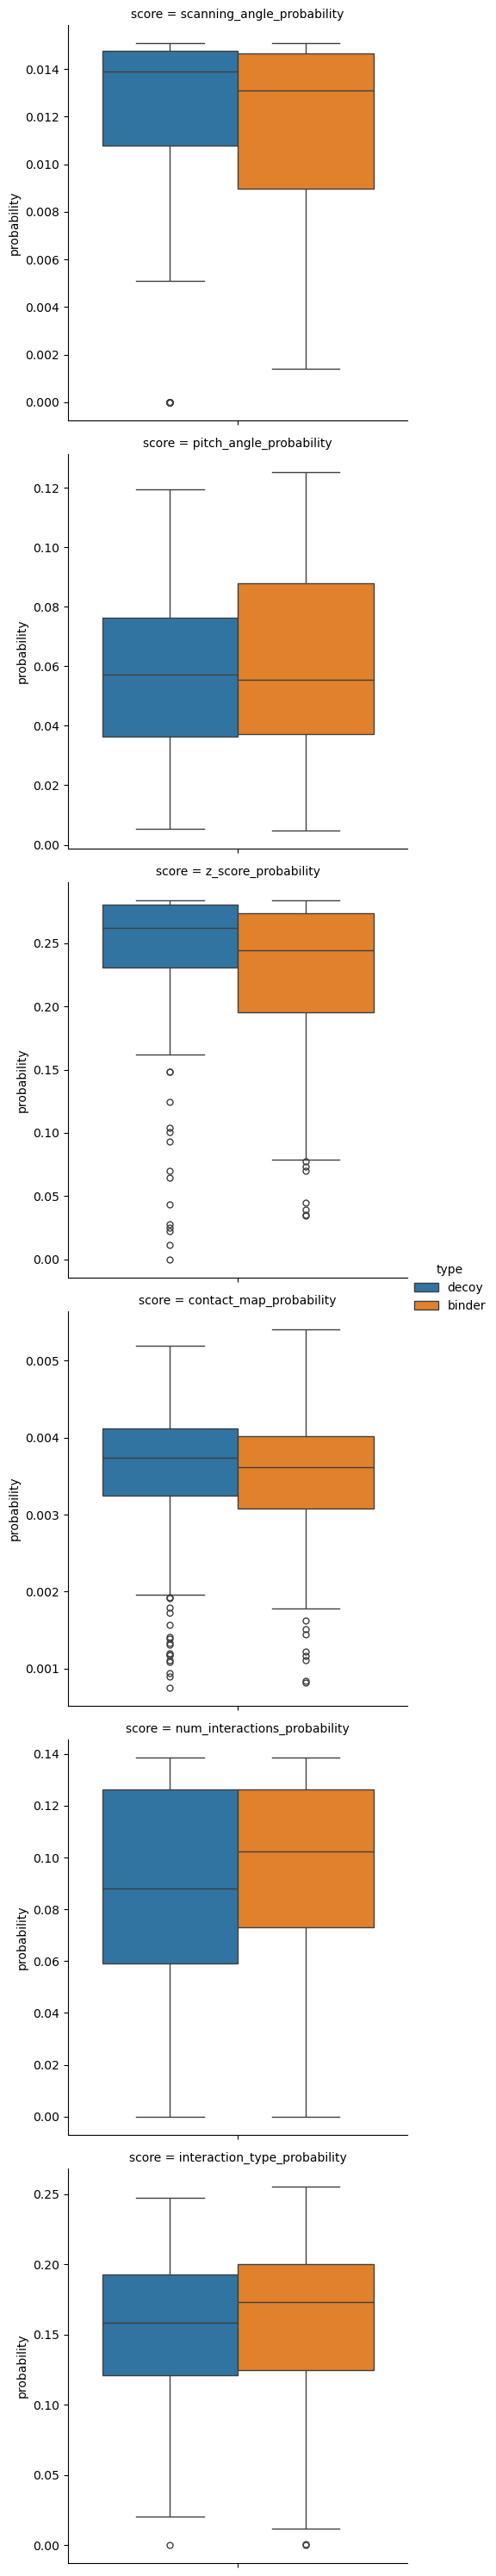

In [32]:
score_probabilities = structure_scores.melt(
    id_vars=['type', 'label'],
    value_vars=structure_probability_names,
    var_name='score',
    value_name='probability',
)
sns.catplot(score_probabilities, row='score', y='probability', hue='type', sharey=False, kind='box')

In [33]:
for score_name, group in score_probabilities.groupby('score'):
    print(score_name)
    print(sklearn.metrics.roc_auc_score(group['label'], group['probability']))

contact_map_probability
0.46060799999999996
interaction_type_probability
0.5383359999999999
num_interactions_probability
0.5407360000000001
pitch_angle_probability
0.502944
scanning_angle_probability
0.45887999999999995
z_score_probability
0.411648


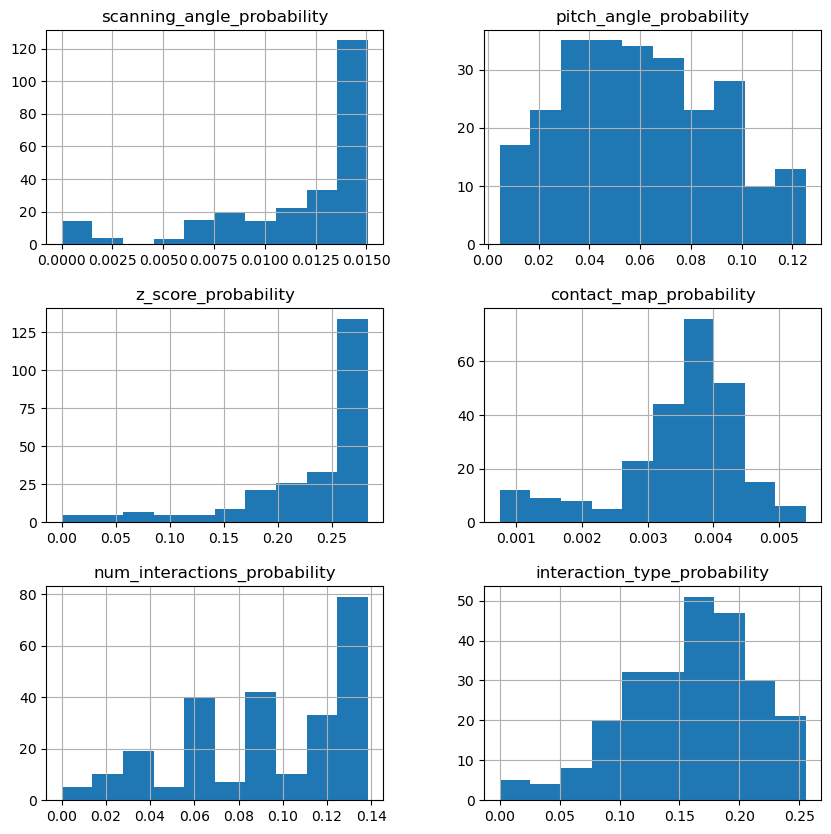

In [34]:
structure_scores[structure_probability_names].hist(figsize=(10, 10))
plt.show()

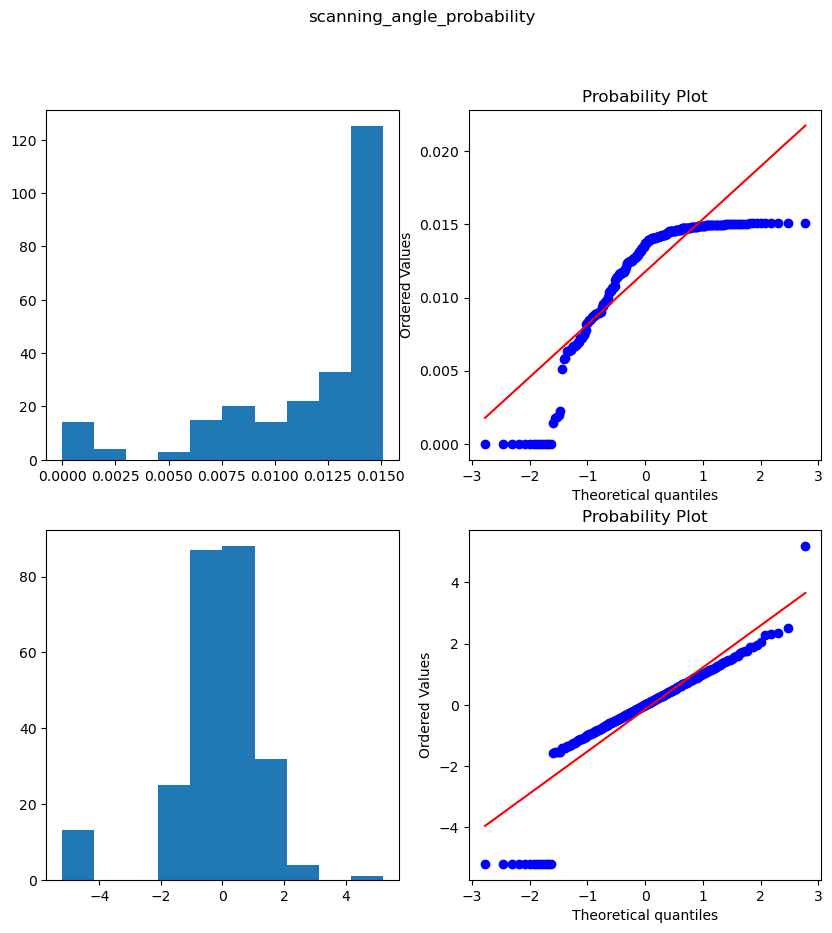

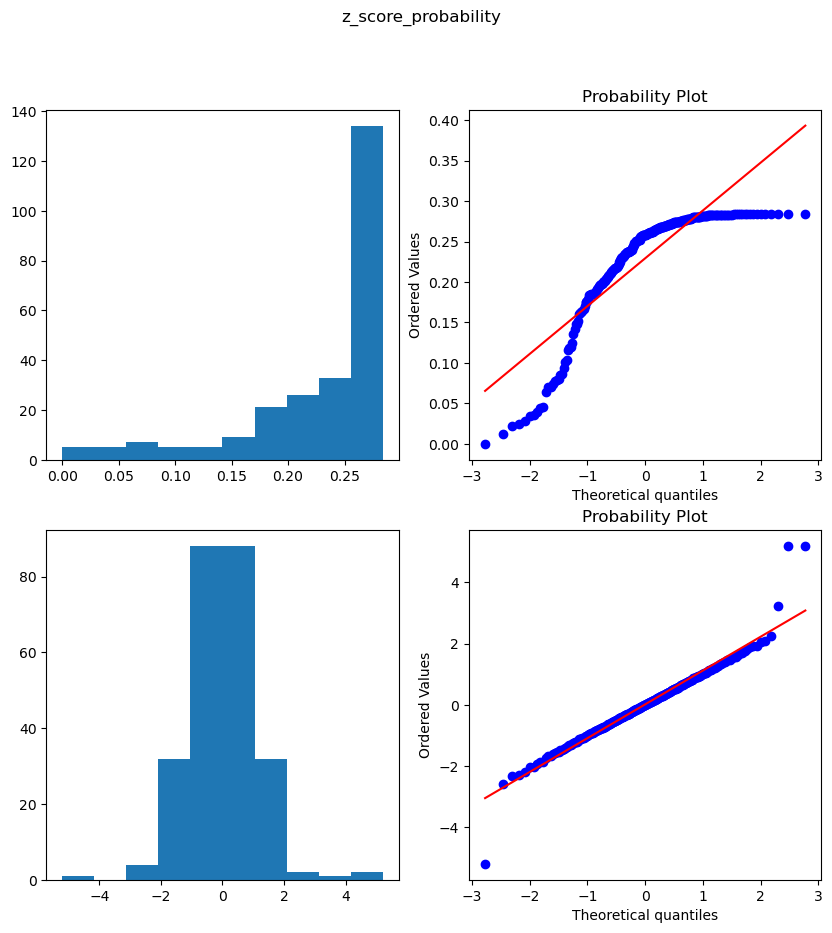

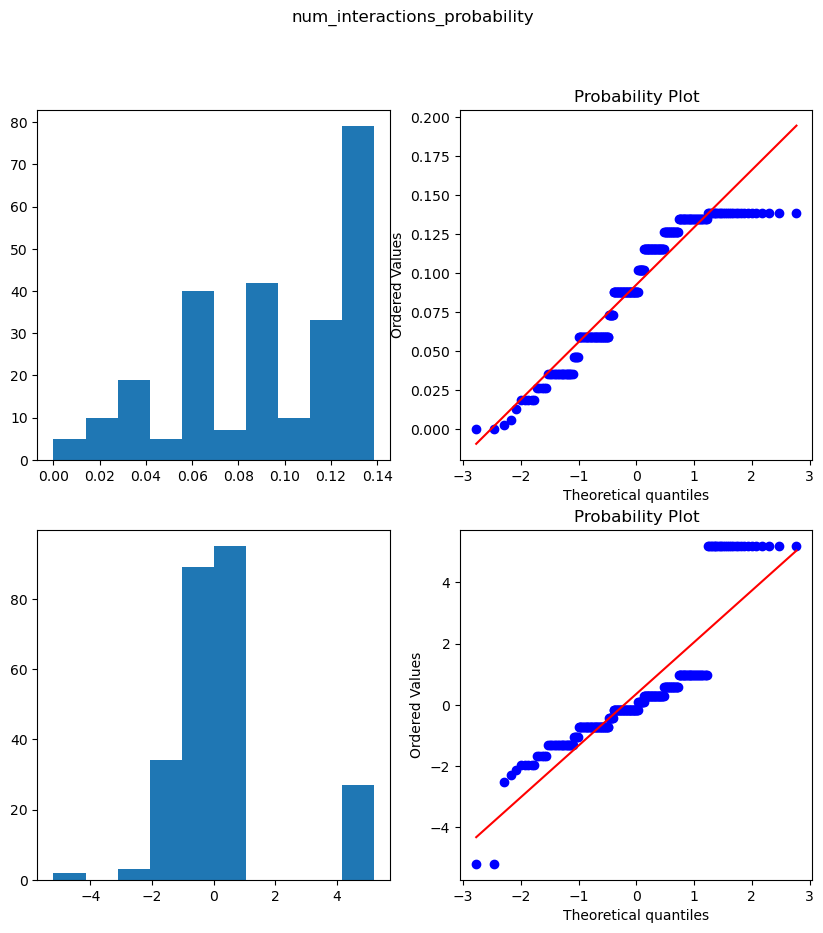

In [35]:
for selected_column in ('scanning_angle_probability', 'z_score_probability', 'num_interactions_probability'):
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    fig.suptitle(selected_column)
    x = structure_scores[selected_column].to_numpy()

    qt = sklearn.preprocessing.QuantileTransformer(output_distribution='normal', n_quantiles=100)
    x_transformed = qt.fit_transform(x.reshape(-1, 1)).squeeze()

    structure_scores[selected_column + '_transformed'] = x_transformed

    axes[0, 0].hist(x)
    scipy.stats.probplot(x, dist=scipy.stats.norm, plot=axes[0, 1])

    axes[1, 0].hist(x_transformed)
    scipy.stats.probplot(x_transformed, dist=scipy.stats.norm, plot=axes[1, 1])

    structure_probability_names = [
        column if column != selected_column else selected_column + '_transformed'
        for column in structure_probability_names
    ]

    plt.show()

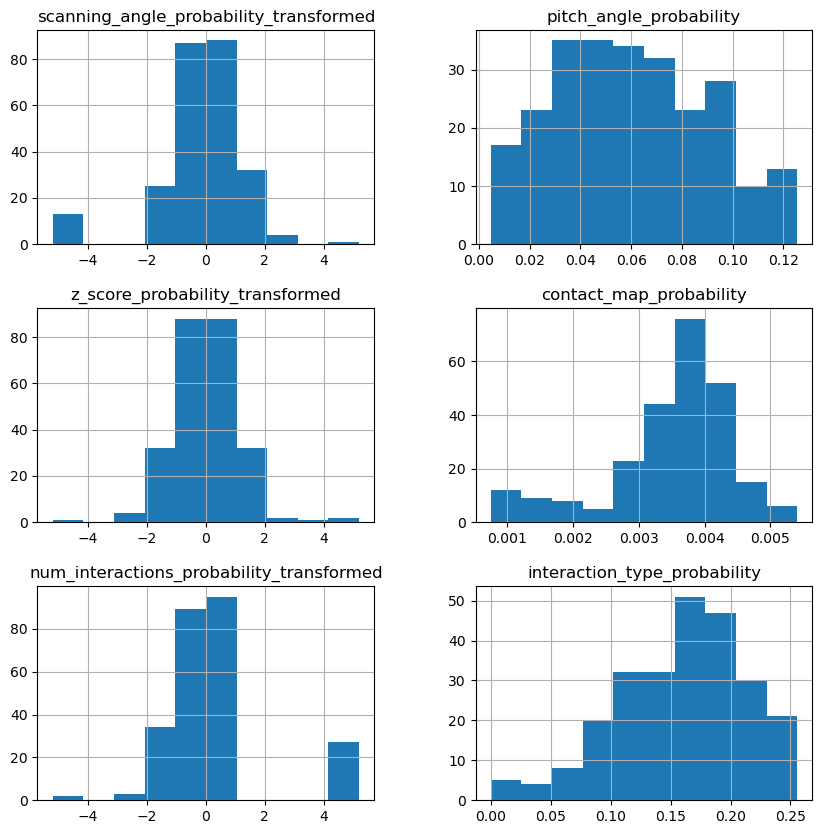

In [36]:
structure_scores[structure_probability_names].hist(figsize=(10, 10))
plt.show()

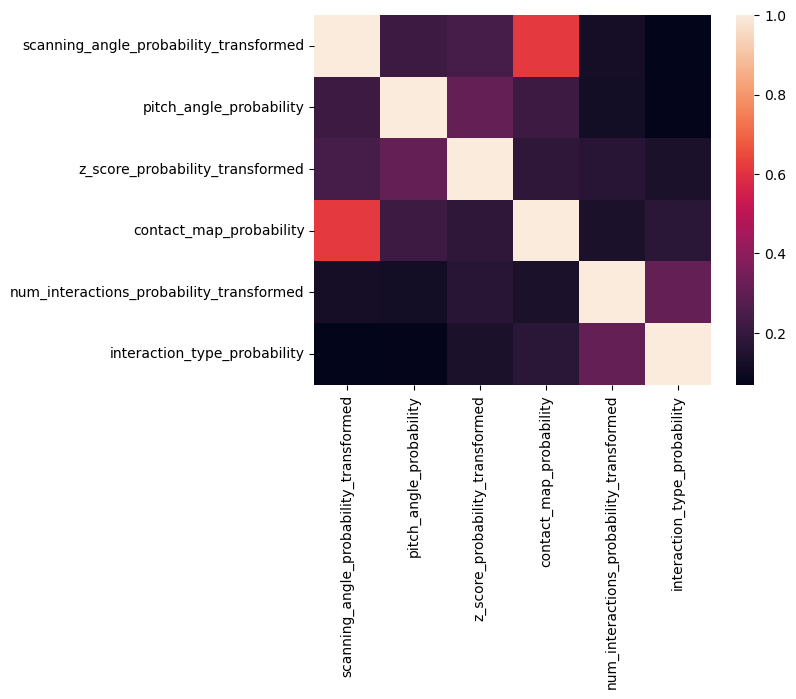

In [37]:
sns.heatmap(structure_scores[structure_probability_names].corr())

plt.show()

In [38]:
structure_probability_names = [
    column for column in structure_probability_names if column not in {'scanning_angle_probability_transformed'}
]

Skipping alpha_chain_alpha_chain_pae_min
alpha_chain_antigen_chain_pae_min
Pearson's correlation: 0.42
                                    OLS Regression Results                                   
Dep. Variable:     alpha_chain_antigen_chain_pae_min   R-squared:                       0.174
Model:                                           OLS   Adj. R-squared:                  0.157
Method:                                Least Squares   F-statistic:                     10.28
Date:                               Thu, 03 Jul 2025   Prob (F-statistic):           5.87e-09
Time:                                       12:11:11   Log-Likelihood:                -706.39
No. Observations:                                250   AIC:                             1425.
Df Residuals:                                    244   BIC:                             1446.
Df Model:                                          5                                         
Covariance Type:                           nonrobus

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-22.029053,9.387770,-2.346569,0.009874,True
z_score_probability_transformed,-0.065342,0.248907,-0.262514,0.396573,False
contact_map_probability,-1108.547183,288.110339,-3.847648,0.000076,True
num_interactions_probability_transformed,-0.126613,0.146509,-0.864200,0.194163,False
interaction_type_probability,-17.571006,5.288948,-3.322212,0.000515,True


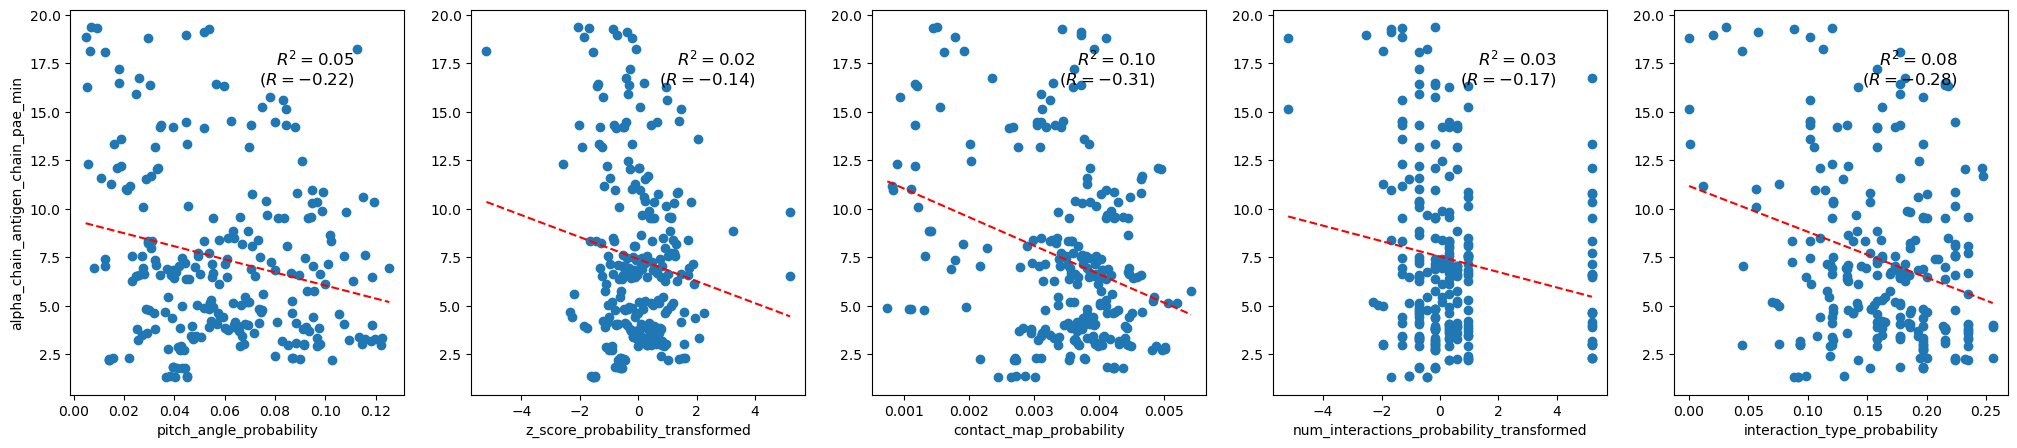

alpha_chain_beta_chain_pae_min
Pearson's correlation: 0.19
                                  OLS Regression Results                                  
Dep. Variable:     alpha_chain_beta_chain_pae_min   R-squared:                       0.038
Model:                                        OLS   Adj. R-squared:                  0.018
Method:                             Least Squares   F-statistic:                     1.914
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):             0.0926
Time:                                    12:11:11   Log-Likelihood:                 205.69
No. Observations:                             250   AIC:                            -399.4
Df Residuals:                                 244   BIC:                            -378.2
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.342167,0.244410,-1.399974,0.081396,False
z_score_probability_transformed,0.012045,0.006480,1.858729,0.967865,False
contact_map_probability,-3.472804,7.500930,-0.462983,0.321895,False
num_interactions_probability_transformed,-0.002578,0.003814,-0.675909,0.249869,False
interaction_type_probability,0.298876,0.137697,2.170528,0.984534,False


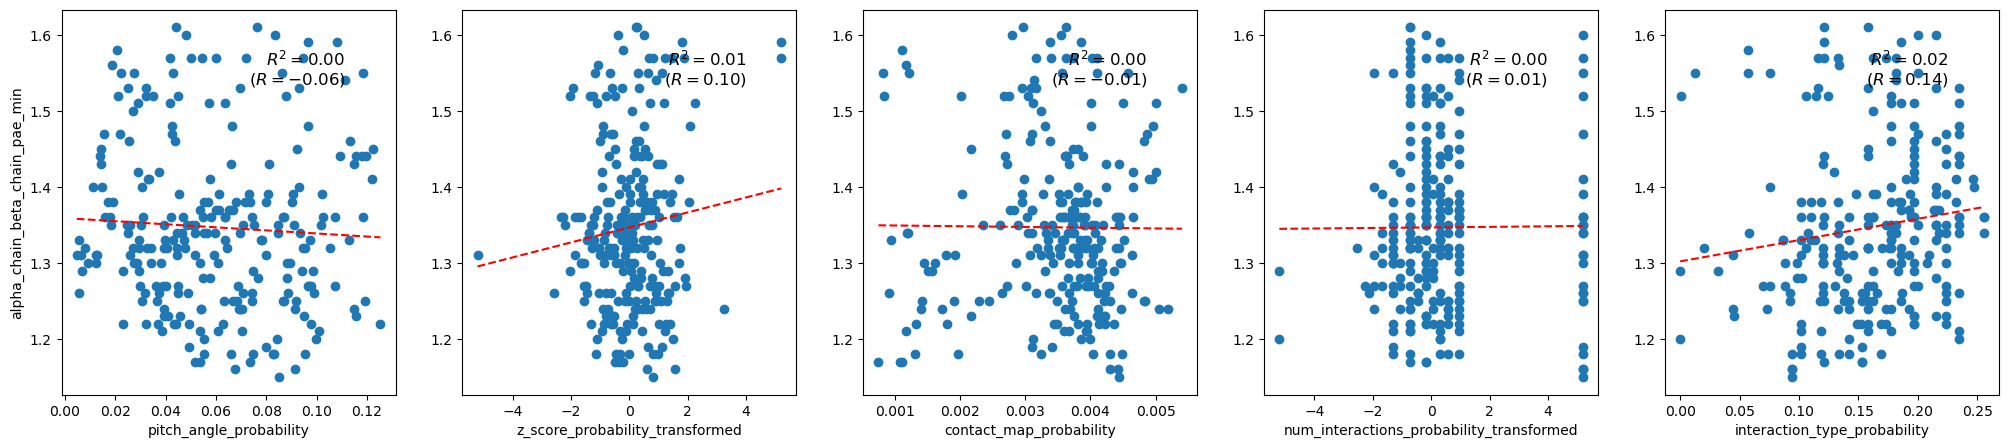

alpha_chain_mhc_chain_1_pae_min
Pearson's correlation: 0.42
                                   OLS Regression Results                                  
Dep. Variable:     alpha_chain_mhc_chain_1_pae_min   R-squared:                       0.180
Model:                                         OLS   Adj. R-squared:                  0.163
Method:                              Least Squares   F-statistic:                     10.71
Date:                             Thu, 03 Jul 2025   Prob (F-statistic):           2.57e-09
Time:                                     12:11:12   Log-Likelihood:                -699.25
No. Observations:                              250   AIC:                             1411.
Df Residuals:                                  244   BIC:                             1432.
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-23.299116,9.123392,-2.553778,0.005633,True
z_score_probability_transformed,0.053308,0.241897,0.220375,0.587118,False
contact_map_probability,-1198.706505,279.996594,-4.281147,0.000013,True
num_interactions_probability_transformed,-0.098429,0.142383,-0.691295,0.245019,False
interaction_type_probability,-16.416010,5.140001,-3.193776,0.000795,True


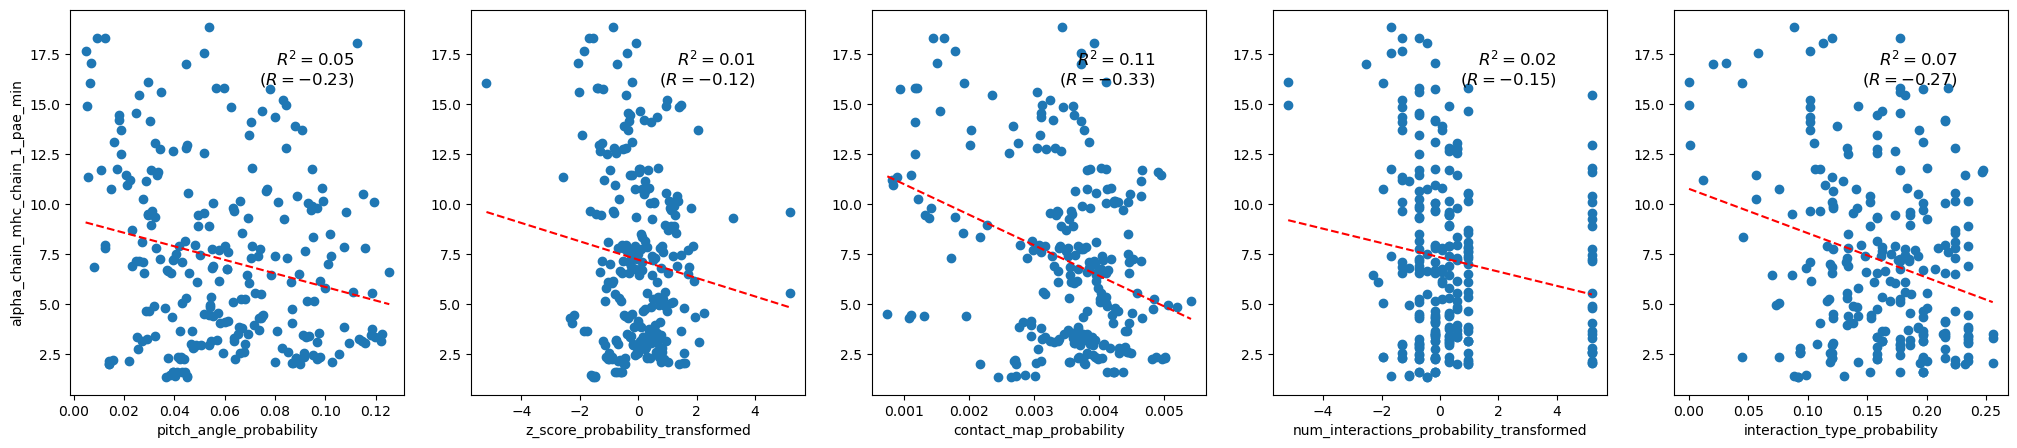

alpha_chain_mhc_chain_2_pae_min
Pearson's correlation: 0.40
                                   OLS Regression Results                                  
Dep. Variable:     alpha_chain_mhc_chain_2_pae_min   R-squared:                       0.158
Model:                                         OLS   Adj. R-squared:                  0.140
Method:                              Least Squares   F-statistic:                     9.132
Date:                             Thu, 03 Jul 2025   Prob (F-statistic):           5.60e-08
Time:                                     12:11:13   Log-Likelihood:                -666.74
No. Observations:                              250   AIC:                             1345.
Df Residuals:                                  244   BIC:                             1367.
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-24.756696,8.010980,-3.090345,0.001116,True
z_score_probability_transformed,-0.029873,0.212403,-0.140644,0.444133,False
contact_map_probability,-856.142007,245.856707,-3.482280,0.000294,True
num_interactions_probability_transformed,-0.039495,0.125022,-0.315903,0.376173,False
interaction_type_probability,-12.679082,4.513282,-2.809282,0.002684,True


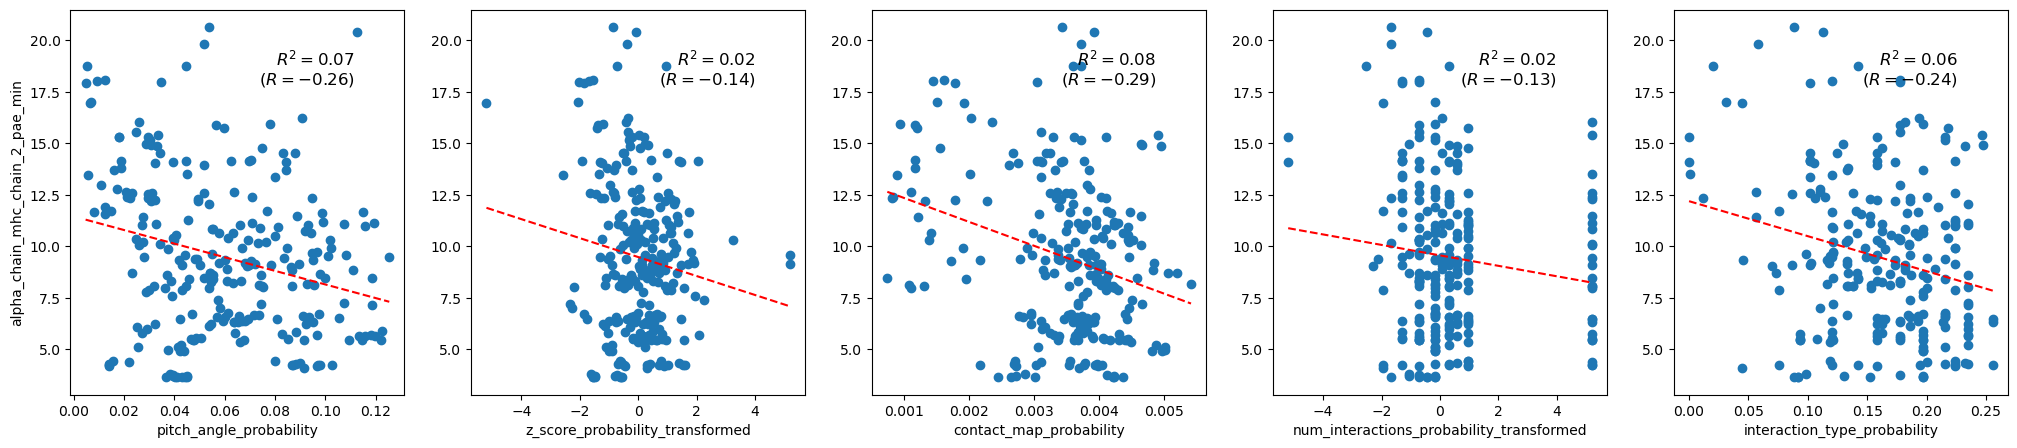

antigen_chain_alpha_chain_pae_min
Pearson's correlation: 0.39
                                    OLS Regression Results                                   
Dep. Variable:     antigen_chain_alpha_chain_pae_min   R-squared:                       0.151
Model:                                           OLS   Adj. R-squared:                  0.134
Method:                                Least Squares   F-statistic:                     8.686
Date:                               Thu, 03 Jul 2025   Prob (F-statistic):           1.35e-07
Time:                                       12:11:14   Log-Likelihood:                -748.56
No. Observations:                                250   AIC:                             1509.
Df Residuals:                                    244   BIC:                             1530.
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-26.222146,11.112620,-2.359673,0.009540,True
z_score_probability_transformed,0.042840,0.294640,0.145399,0.557742,False
contact_map_probability,-1175.144497,341.045931,-3.445707,0.000335,True
num_interactions_probability_transformed,-0.154682,0.173428,-0.891908,0.186661,False
interaction_type_probability,-19.483253,6.260706,-3.111990,0.001040,True


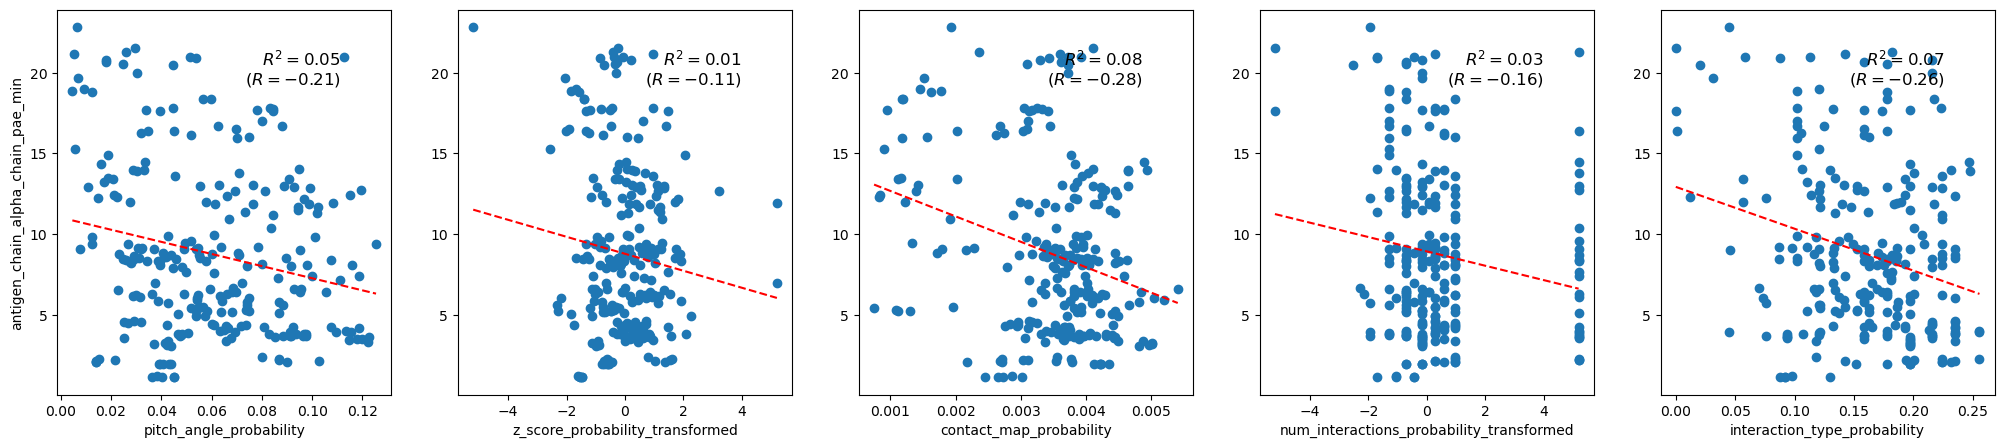

Skipping antigen_chain_antigen_chain_pae_min
antigen_chain_beta_chain_pae_min
Pearson's correlation: 0.36
                                   OLS Regression Results                                   
Dep. Variable:     antigen_chain_beta_chain_pae_min   R-squared:                       0.127
Model:                                          OLS   Adj. R-squared:                  0.110
Method:                               Least Squares   F-statistic:                     7.128
Date:                              Thu, 03 Jul 2025   Prob (F-statistic):           3.04e-06
Time:                                      12:11:14   Log-Likelihood:                -738.24
No. Observations:                               250   AIC:                             1488.
Df Residuals:                                   244   BIC:                             1510.
Df Model:                                         5                                         
Covariance Type:                          nonrobust      

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-19.603966,10.663035,-1.838498,0.033602,True
z_score_probability_transformed,-0.039223,0.282719,-0.138733,0.444888,False
contact_map_probability,-963.619891,327.248179,-2.944615,0.001773,True
num_interactions_probability_transformed,-0.172219,0.166411,-1.034898,0.150870,False
interaction_type_probability,-17.815171,6.007415,-2.965530,0.001661,True


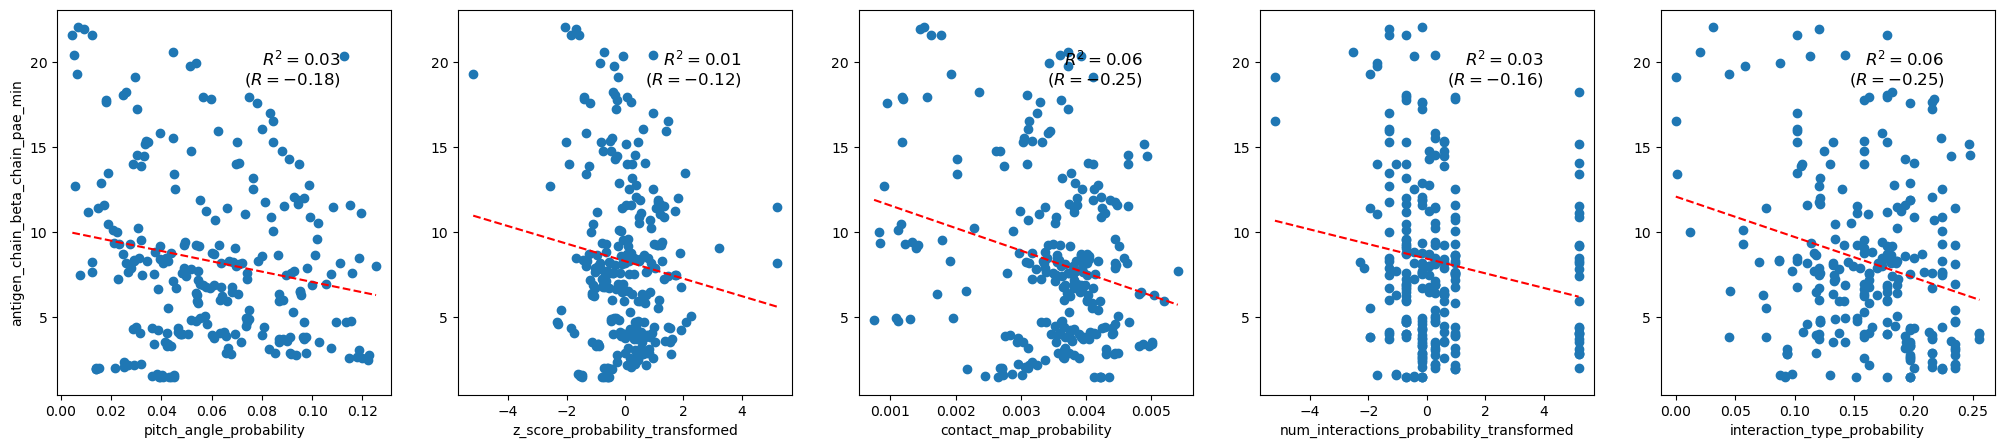

antigen_chain_mhc_chain_1_pae_min
Pearson's correlation: 0.28
                                    OLS Regression Results                                   
Dep. Variable:     antigen_chain_mhc_chain_1_pae_min   R-squared:                       0.077
Model:                                           OLS   Adj. R-squared:                  0.058
Method:                                Least Squares   F-statistic:                     4.081
Date:                               Thu, 03 Jul 2025   Prob (F-statistic):            0.00141
Time:                                       12:11:15   Log-Likelihood:                -141.60
No. Observations:                                250   AIC:                             295.2
Df Residuals:                                    244   BIC:                             316.3
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,2.704951,0.980434,2.758933,0.996881,False
z_score_probability_transformed,-0.068146,0.025995,-2.621475,0.004653,True
contact_map_probability,71.792997,30.089484,2.385983,0.991101,False
num_interactions_probability_transformed,-0.024330,0.015301,-1.590070,0.056557,False
interaction_type_probability,0.190297,0.552364,0.344514,0.634622,False


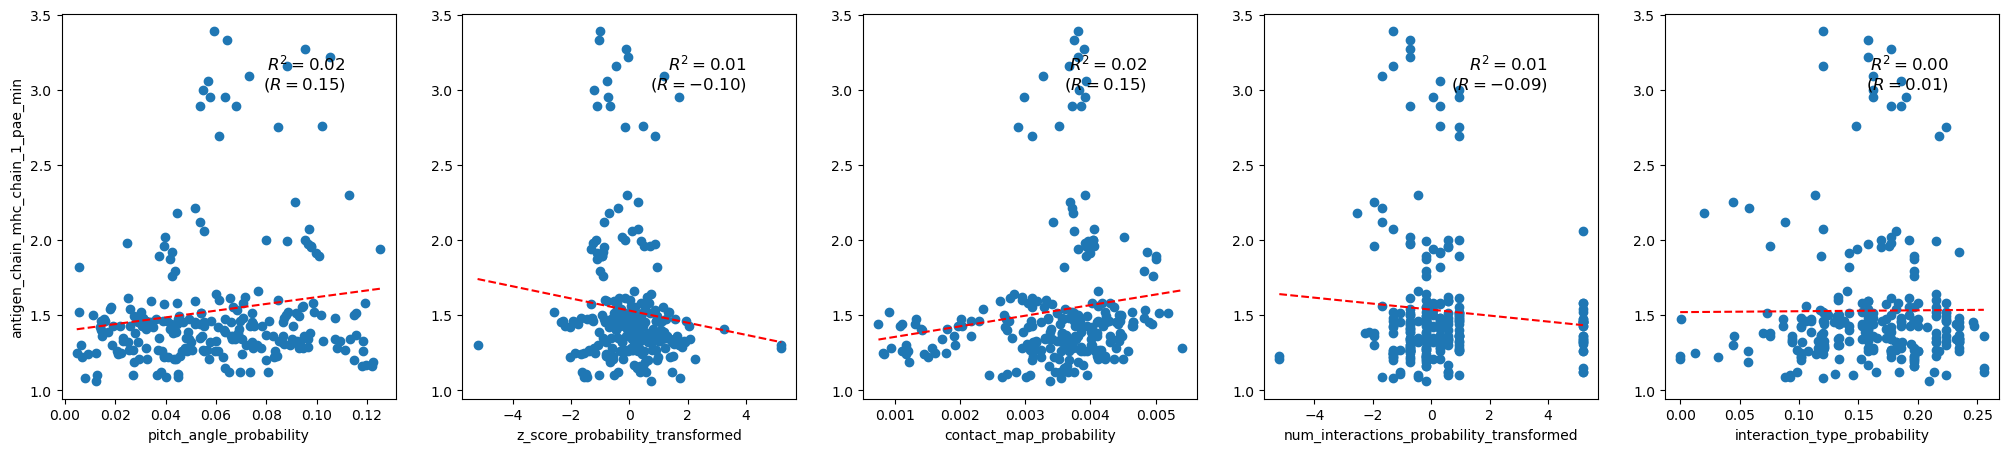

antigen_chain_mhc_chain_2_pae_min
Pearson's correlation: 0.21
                                    OLS Regression Results                                   
Dep. Variable:     antigen_chain_mhc_chain_2_pae_min   R-squared:                       0.046
Model:                                           OLS   Adj. R-squared:                  0.026
Method:                                Least Squares   F-statistic:                     2.342
Date:                               Thu, 03 Jul 2025   Prob (F-statistic):             0.0422
Time:                                       12:11:15   Log-Likelihood:                -313.39
No. Observations:                                250   AIC:                             638.8
Df Residuals:                                    244   BIC:                             659.9
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,3.070430,1.949176,1.575245,0.941752,False
z_score_probability_transformed,-0.063440,0.051680,-1.227541,0.110401,False
contact_map_probability,134.530498,59.820138,2.248917,0.987295,False
num_interactions_probability_transformed,-0.053243,0.030420,-1.750287,0.040663,True
interaction_type_probability,-0.037338,1.098140,-0.034001,0.486452,False


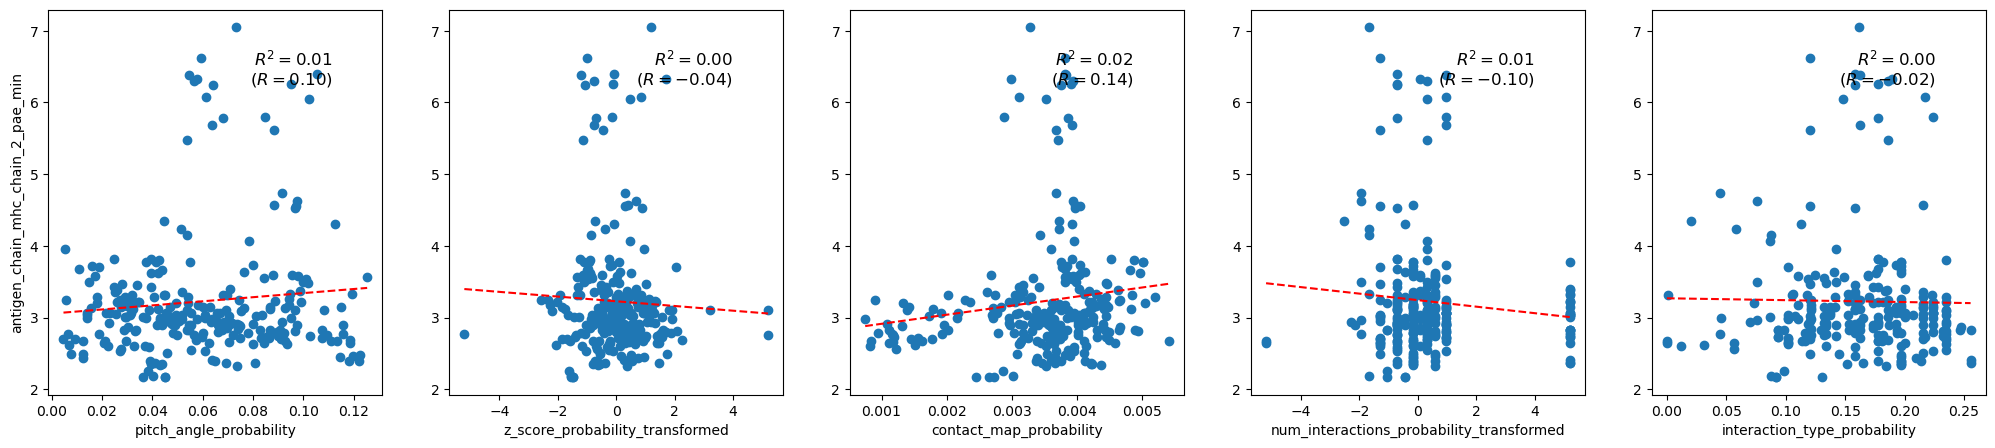

beta_chain_alpha_chain_pae_min
Pearson's correlation: 0.23
                                  OLS Regression Results                                  
Dep. Variable:     beta_chain_alpha_chain_pae_min   R-squared:                       0.052
Model:                                        OLS   Adj. R-squared:                  0.033
Method:                             Least Squares   F-statistic:                     2.685
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):             0.0220
Time:                                    12:11:16   Log-Likelihood:                 219.38
No. Observations:                             250   AIC:                            -426.8
Df Residuals:                                 244   BIC:                            -405.6
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.404875,0.231381,-1.749822,0.040703,True
z_score_probability_transformed,0.006093,0.006135,0.993153,0.839190,False
contact_map_probability,-9.356596,7.101071,-1.317632,0.094431,False
num_interactions_probability_transformed,0.001713,0.003611,0.474296,0.682144,False
interaction_type_probability,0.345885,0.130357,2.653368,0.995754,False


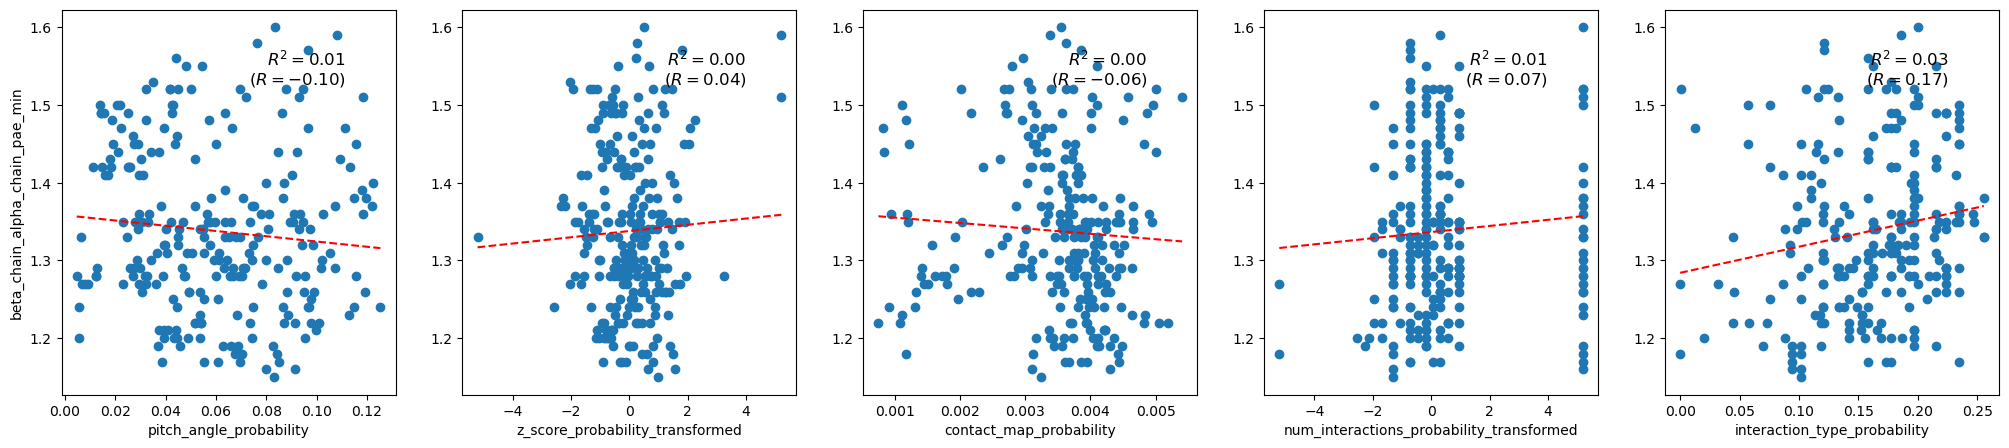

beta_chain_antigen_chain_pae_min
Pearson's correlation: 0.41
                                   OLS Regression Results                                   
Dep. Variable:     beta_chain_antigen_chain_pae_min   R-squared:                       0.165
Model:                                          OLS   Adj. R-squared:                  0.148
Method:                               Least Squares   F-statistic:                     9.661
Date:                              Thu, 03 Jul 2025   Prob (F-statistic):           1.98e-08
Time:                                      12:11:16   Log-Likelihood:                -706.64
No. Observations:                               250   AIC:                             1425.
Df Residuals:                                   244   BIC:                             1446.
Df Model:                                         5                                         
Covariance Type:                          nonrobust                                         
         

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-20.298478,9.396862,-2.160134,0.015868,True
z_score_probability_transformed,-0.023157,0.249148,-0.092947,0.463011,False
contact_map_probability,-1034.108666,288.389354,-3.585807,0.000203,True
num_interactions_probability_transformed,-0.139198,0.146651,-0.949176,0.171735,False
interaction_type_probability,-18.383427,5.294070,-3.472457,0.000305,True


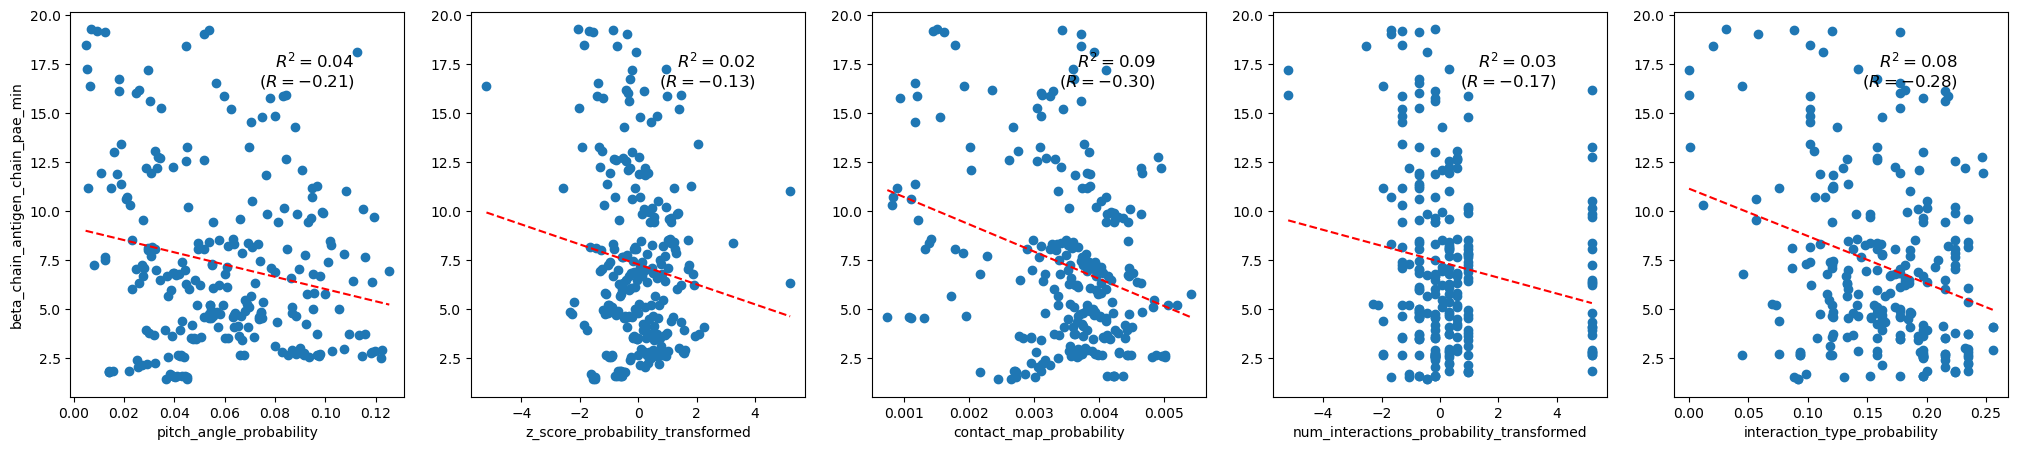

Skipping beta_chain_beta_chain_pae_min
beta_chain_mhc_chain_1_pae_min
Pearson's correlation: 0.41
                                  OLS Regression Results                                  
Dep. Variable:     beta_chain_mhc_chain_1_pae_min   R-squared:                       0.167
Model:                                        OLS   Adj. R-squared:                  0.150
Method:                             Least Squares   F-statistic:                     9.783
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):           1.56e-08
Time:                                    12:11:17   Log-Likelihood:                -698.73
No. Observations:                             250   AIC:                             1409.
Df Residuals:                                 244   BIC:                             1431.
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-21.415000,9.104228,-2.352204,0.009729,True
z_score_probability_transformed,0.021104,0.241389,0.087428,0.534799,False
contact_map_probability,-1099.608569,279.408426,-3.935488,0.000054,True
num_interactions_probability_transformed,-0.088684,0.142084,-0.624164,0.266552,False
interaction_type_probability,-16.817690,5.129203,-3.278811,0.000597,True


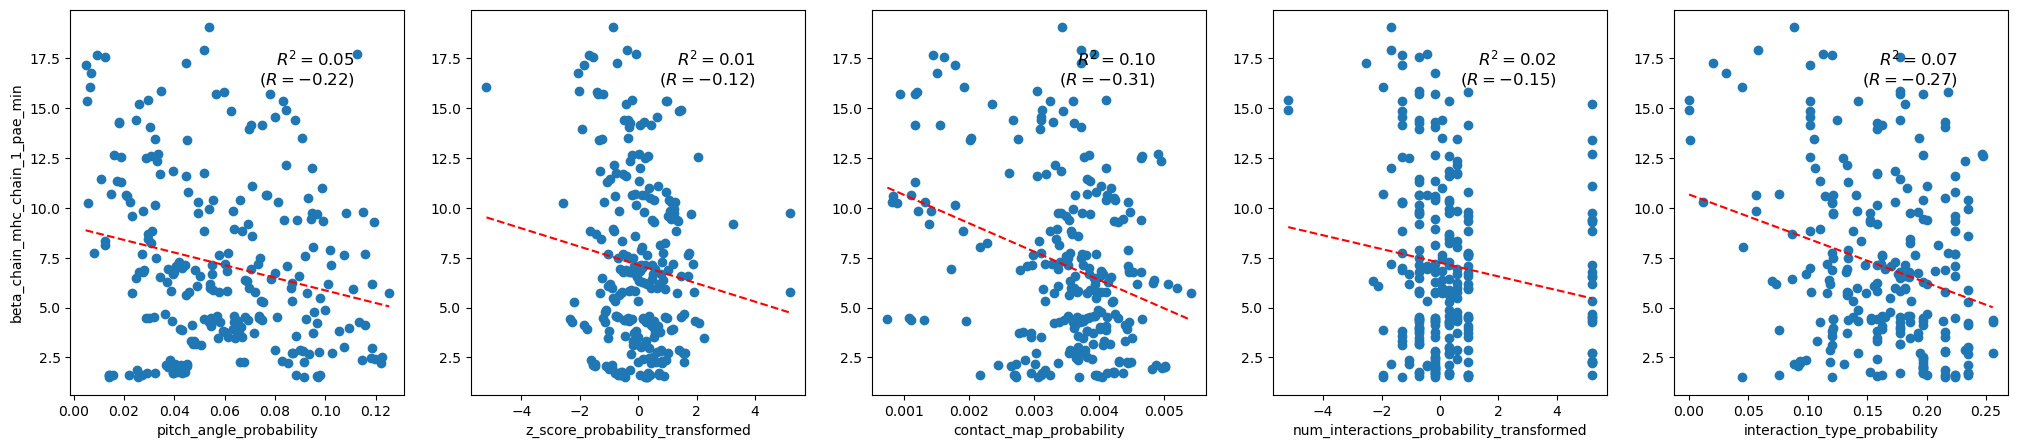

beta_chain_mhc_chain_2_pae_min
Pearson's correlation: 0.40
                                  OLS Regression Results                                  
Dep. Variable:     beta_chain_mhc_chain_2_pae_min   R-squared:                       0.158
Model:                                        OLS   Adj. R-squared:                  0.141
Method:                             Least Squares   F-statistic:                     9.182
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):           5.07e-08
Time:                                    12:11:18   Log-Likelihood:                -666.62
No. Observations:                             250   AIC:                             1345.
Df Residuals:                                 244   BIC:                             1366.
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-22.264855,8.006962,-2.780687,0.002924,True
z_score_probability_transformed,-0.009961,0.212296,-0.046918,0.481308,False
contact_map_probability,-880.032549,245.733388,-3.581249,0.000206,True
num_interactions_probability_transformed,-0.043896,0.124960,-0.351279,0.362841,False
interaction_type_probability,-13.859329,4.511018,-3.072328,0.001182,True


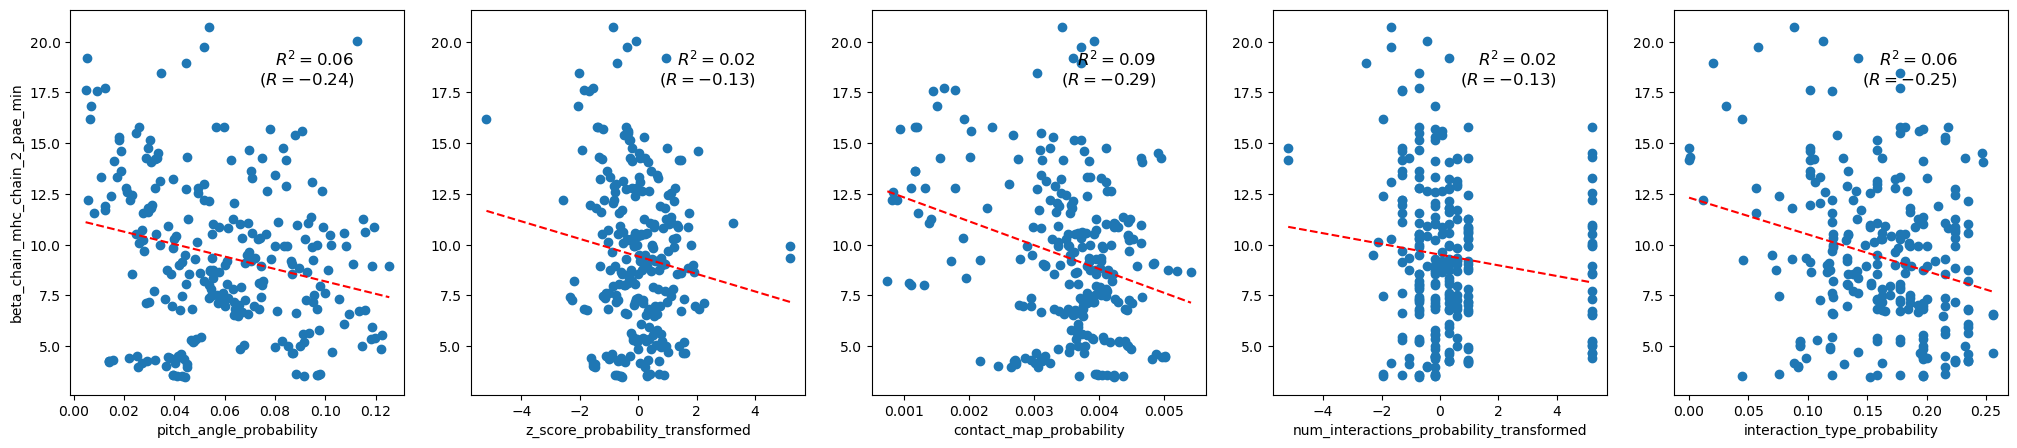

cdr_pmhc_pae_score
Pearson's correlation: 0.43
                            OLS Regression Results                            
Dep. Variable:     cdr_pmhc_pae_score   R-squared:                       0.182
Model:                            OLS   Adj. R-squared:                  0.165
Method:                 Least Squares   F-statistic:                     10.87
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           1.86e-09
Time:                        12:11:18   Log-Likelihood:                -746.08
No. Observations:                 250   AIC:                             1504.
Df Residuals:                     244   BIC:                             1525.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-33.948412,11.002744,-3.085449,0.001133,True
z_score_probability_transformed,0.120850,0.291726,0.414256,0.660475,False
contact_map_probability,-1452.536646,337.673836,-4.301597,0.000012,True
num_interactions_probability_transformed,-0.048005,0.171713,-0.279568,0.390023,False
interaction_type_probability,-19.004955,6.198803,-3.065907,0.001207,True


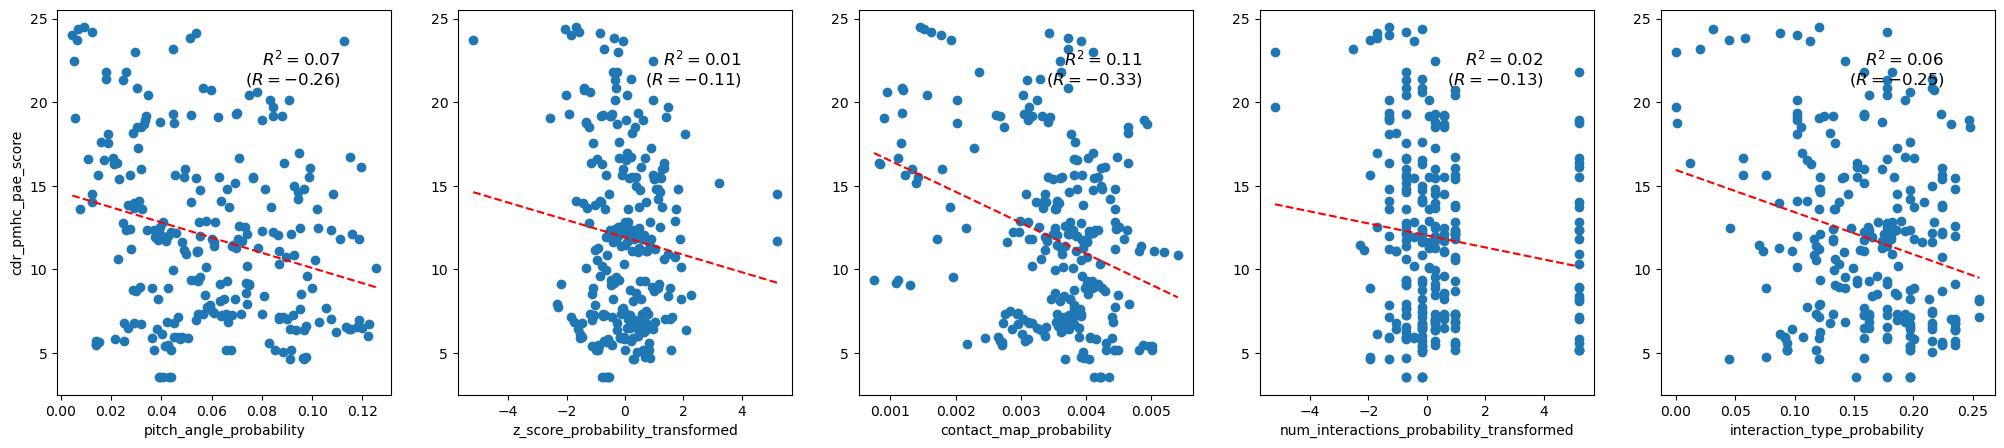

combined_pae_min
Pearson's correlation: 0.40
                            OLS Regression Results                            
Dep. Variable:       combined_pae_min   R-squared:                       0.159
Model:                            OLS   Adj. R-squared:                  0.141
Method:                 Least Squares   F-statistic:                     9.198
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           4.91e-08
Time:                        12:11:19   Log-Likelihood:                -618.61
No. Observations:                 250   AIC:                             1249.
Df Residuals:                     244   BIC:                             1270.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-15.037284,6.607977,-2.275626,0.011868,True
z_score_probability_transformed,0.003798,0.175204,0.021680,0.508640,False
contact_map_probability,-744.490140,202.798573,-3.671082,0.000148,True
num_interactions_probability_transformed,-0.085924,0.103127,-0.833188,0.202777,False
interaction_type_probability,-11.856078,3.722848,-3.184679,0.000819,True


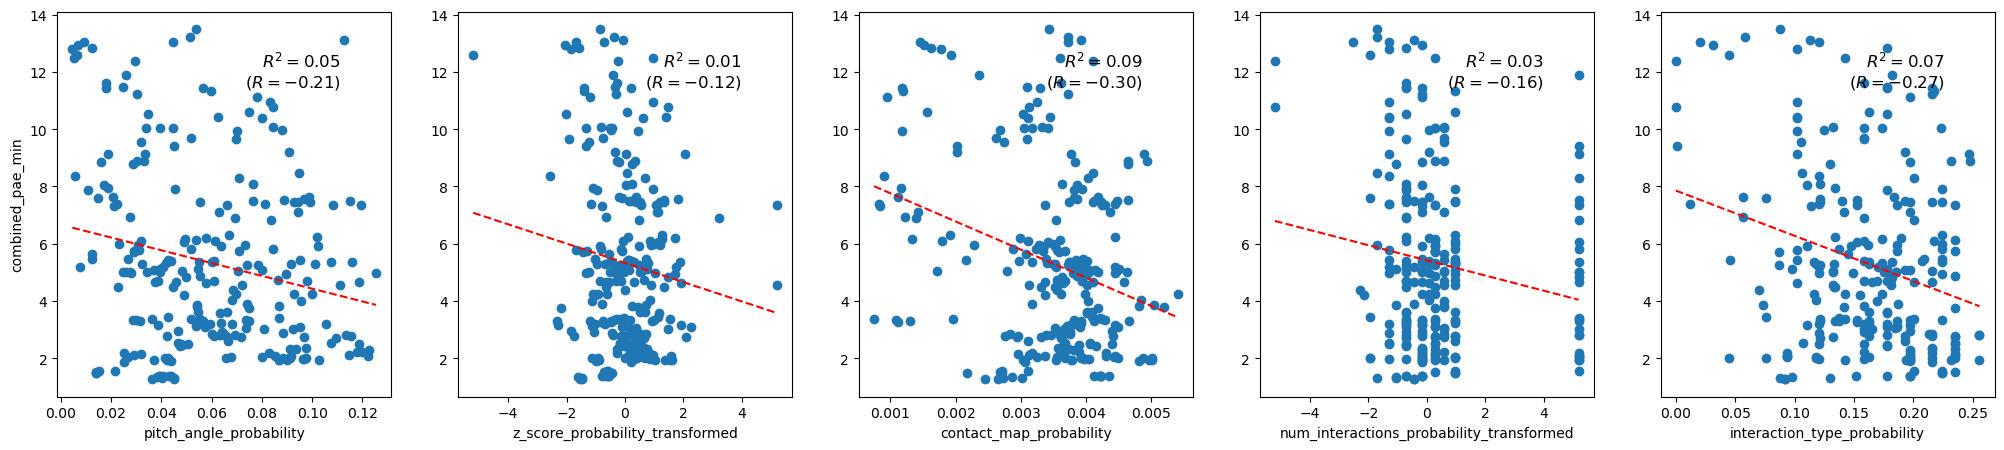

mhc_chain_1_alpha_chain_pae_min
Pearson's correlation: 0.39
                                   OLS Regression Results                                  
Dep. Variable:     mhc_chain_1_alpha_chain_pae_min   R-squared:                       0.154
Model:                                         OLS   Adj. R-squared:                  0.136
Method:                              Least Squares   F-statistic:                     8.860
Date:                             Thu, 03 Jul 2025   Prob (F-statistic):           9.58e-08
Time:                                     12:11:19   Log-Likelihood:                -761.92
No. Observations:                              250   AIC:                             1536.
Df Residuals:                                  244   BIC:                             1557.
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-28.436724,11.722653,-2.425792,0.008001,True
z_score_probability_transformed,0.089027,0.310814,0.286431,0.612605,False
contact_map_probability,-1327.137128,359.767815,-3.688871,0.000139,True
num_interactions_probability_transformed,-0.135443,0.182948,-0.740335,0.229904,False
interaction_type_probability,-20.028096,6.604390,-3.032543,0.001343,True


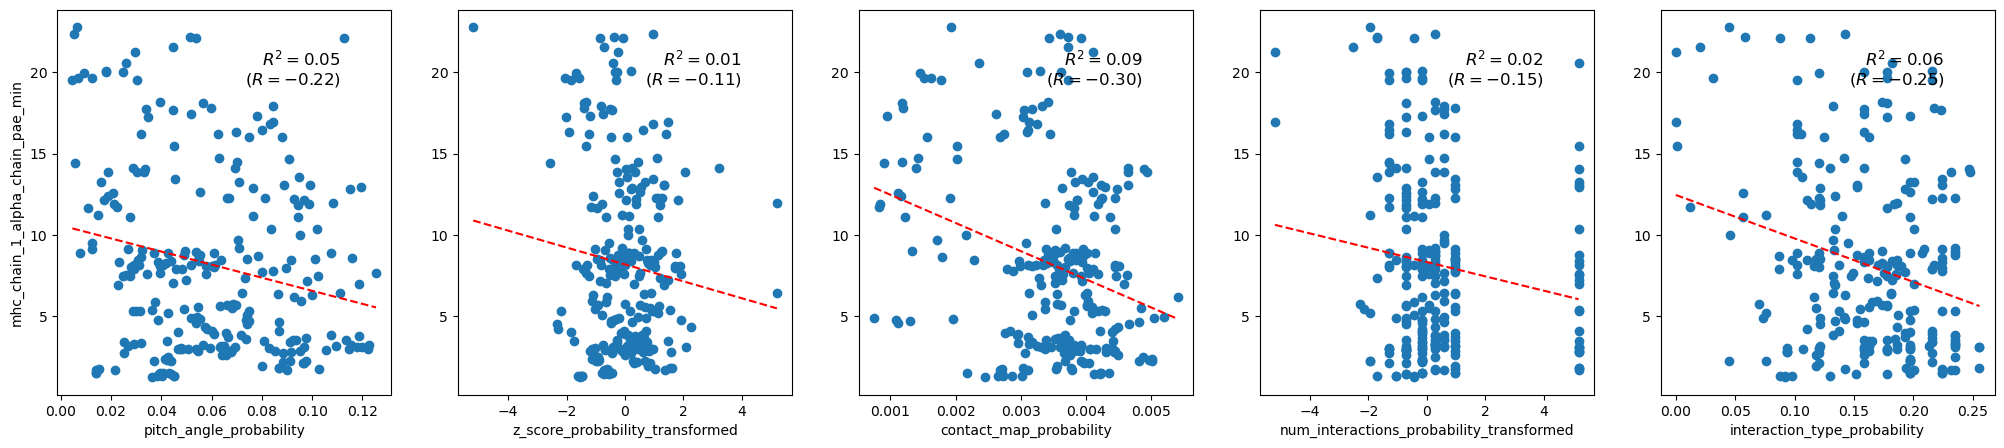

mhc_chain_1_antigen_chain_pae_min
Pearson's correlation: 0.23
                                    OLS Regression Results                                   
Dep. Variable:     mhc_chain_1_antigen_chain_pae_min   R-squared:                       0.051
Model:                                           OLS   Adj. R-squared:                  0.032
Method:                                Least Squares   F-statistic:                     2.641
Date:                               Thu, 03 Jul 2025   Prob (F-statistic):             0.0240
Time:                                       12:11:20   Log-Likelihood:                 2.3915
No. Observations:                                250   AIC:                             7.217
Df Residuals:                                    244   BIC:                             28.35
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,1.110674,0.551159,2.015162,0.977508,False
z_score_probability_transformed,-0.023302,0.014613,-1.594570,0.056051,False
contact_map_probability,23.131357,16.915044,1.367502,0.913637,False
num_interactions_probability_transformed,-0.017278,0.008602,-2.008691,0.022836,True
interaction_type_probability,-0.245055,0.310516,-0.789189,0.215384,False


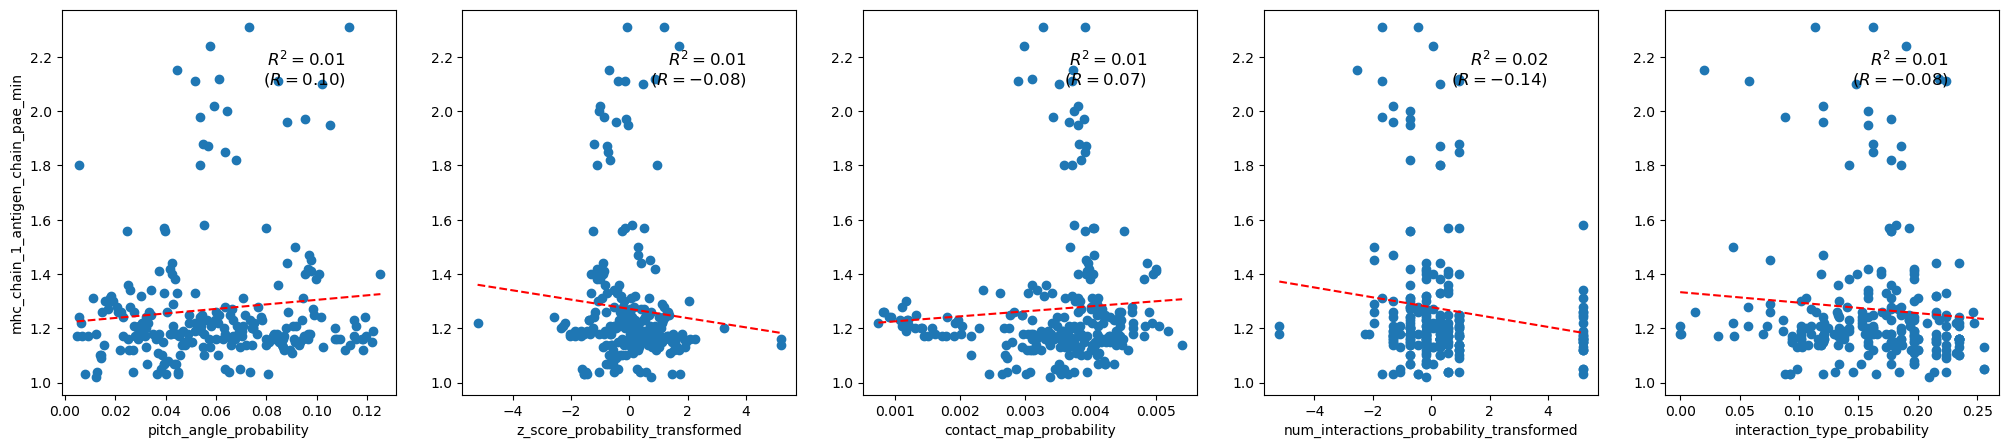

mhc_chain_1_beta_chain_pae_min
Pearson's correlation: 0.37
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain_1_beta_chain_pae_min   R-squared:                       0.139
Model:                                        OLS   Adj. R-squared:                  0.122
Method:                             Least Squares   F-statistic:                     7.905
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):           6.40e-07
Time:                                    12:11:21   Log-Likelihood:                -750.21
No. Observations:                             250   AIC:                             1512.
Df Residuals:                                 244   BIC:                             1534.
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-23.809245,11.185928,-2.128500,0.017149,True
z_score_probability_transformed,0.018109,0.296583,0.061058,0.524319,False
contact_map_probability,-1206.171134,343.295747,-3.513504,0.000263,True
num_interactions_probability_transformed,-0.119364,0.174572,-0.683751,0.247391,False
interaction_type_probability,-18.182176,6.302006,-2.885141,0.002131,True


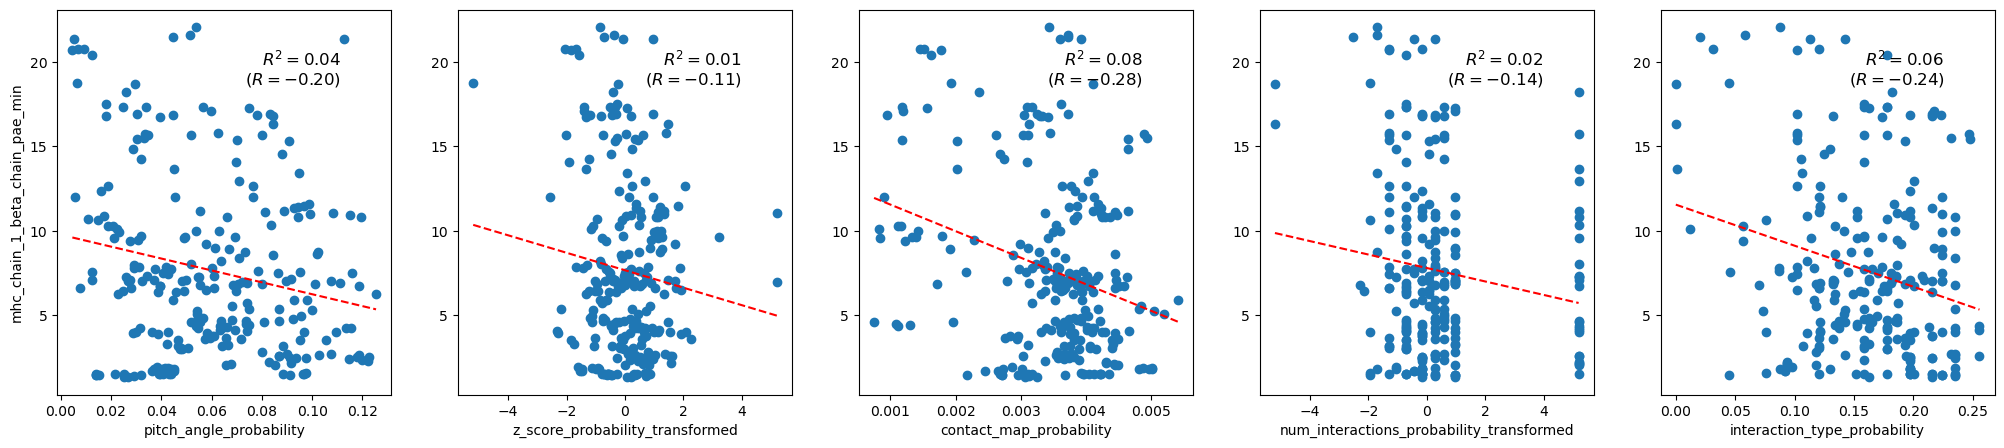

Skipping mhc_chain_1_mhc_chain_1_pae_min
mhc_chain_1_mhc_chain_2_pae_min
Pearson's correlation: 0.36
                                   OLS Regression Results                                  
Dep. Variable:     mhc_chain_1_mhc_chain_2_pae_min   R-squared:                       0.129
Model:                                         OLS   Adj. R-squared:                  0.111
Method:                              Least Squares   F-statistic:                     7.197
Date:                             Thu, 03 Jul 2025   Prob (F-statistic):           2.65e-06
Time:                                     12:11:21   Log-Likelihood:                 418.20
No. Observations:                              250   AIC:                            -824.4
Df Residuals:                                  244   BIC:                            -803.3
Df Model:                                        5                                         
Covariance Type:                         nonrobust                     

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.159528,0.104459,1.527180,0.935994,False
z_score_probability_transformed,-0.003162,0.002770,-1.141828,0.127322,False
contact_map_probability,-14.238637,3.205853,-4.441450,0.000007,True
num_interactions_probability_transformed,-0.004635,0.001630,-2.843103,0.002423,True
interaction_type_probability,0.006908,0.058851,0.117376,0.546671,False


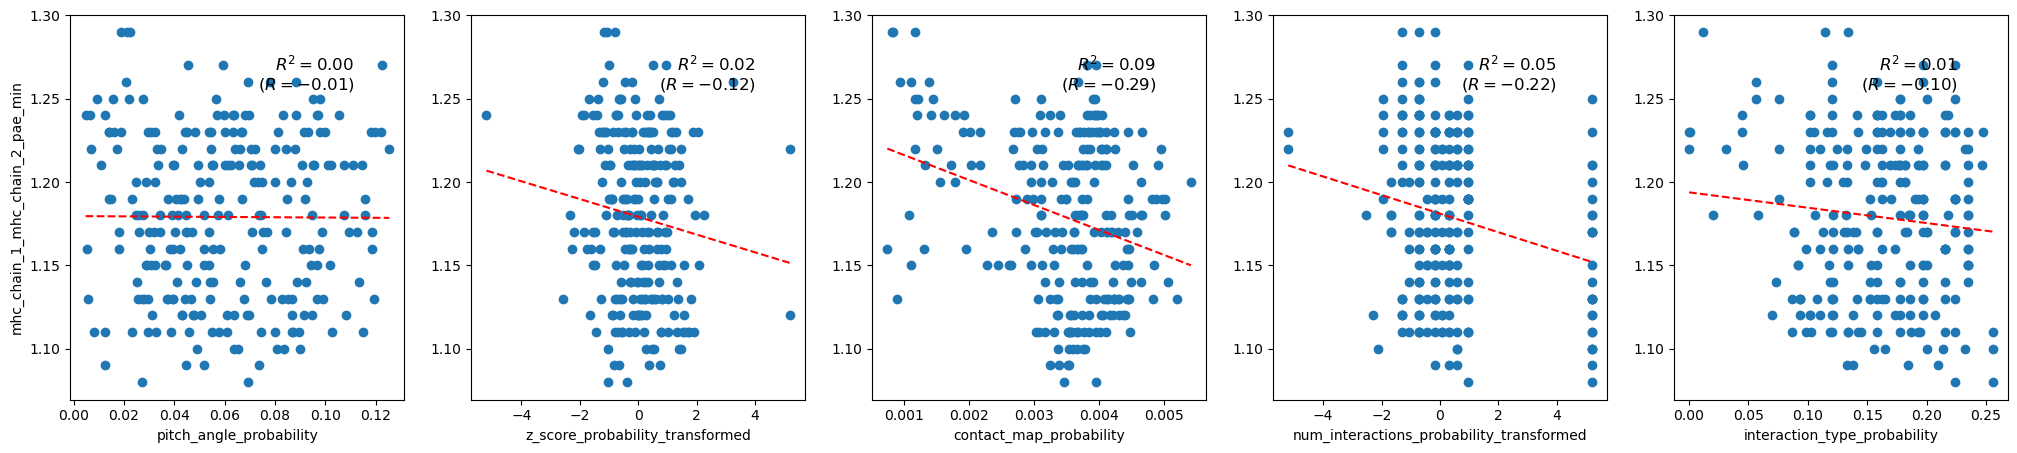

mhc_chain_2_alpha_chain_pae_min
Pearson's correlation: 0.39
                                   OLS Regression Results                                  
Dep. Variable:     mhc_chain_2_alpha_chain_pae_min   R-squared:                       0.149
Model:                                         OLS   Adj. R-squared:                  0.132
Method:                              Least Squares   F-statistic:                     8.541
Date:                             Thu, 03 Jul 2025   Prob (F-statistic):           1.81e-07
Time:                                     12:11:22   Log-Likelihood:                -748.62
No. Observations:                              250   AIC:                             1509.
Df Residuals:                                  244   BIC:                             1530.
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-26.253002,11.115111,-2.361920,0.009483,True
z_score_probability_transformed,0.088897,0.294706,0.301647,0.618411,False
contact_map_probability,-1242.833912,341.122374,-3.643367,0.000164,True
num_interactions_probability_transformed,-0.137072,0.173467,-0.790190,0.215092,False
interaction_type_probability,-18.408233,6.262109,-2.939622,0.001801,True


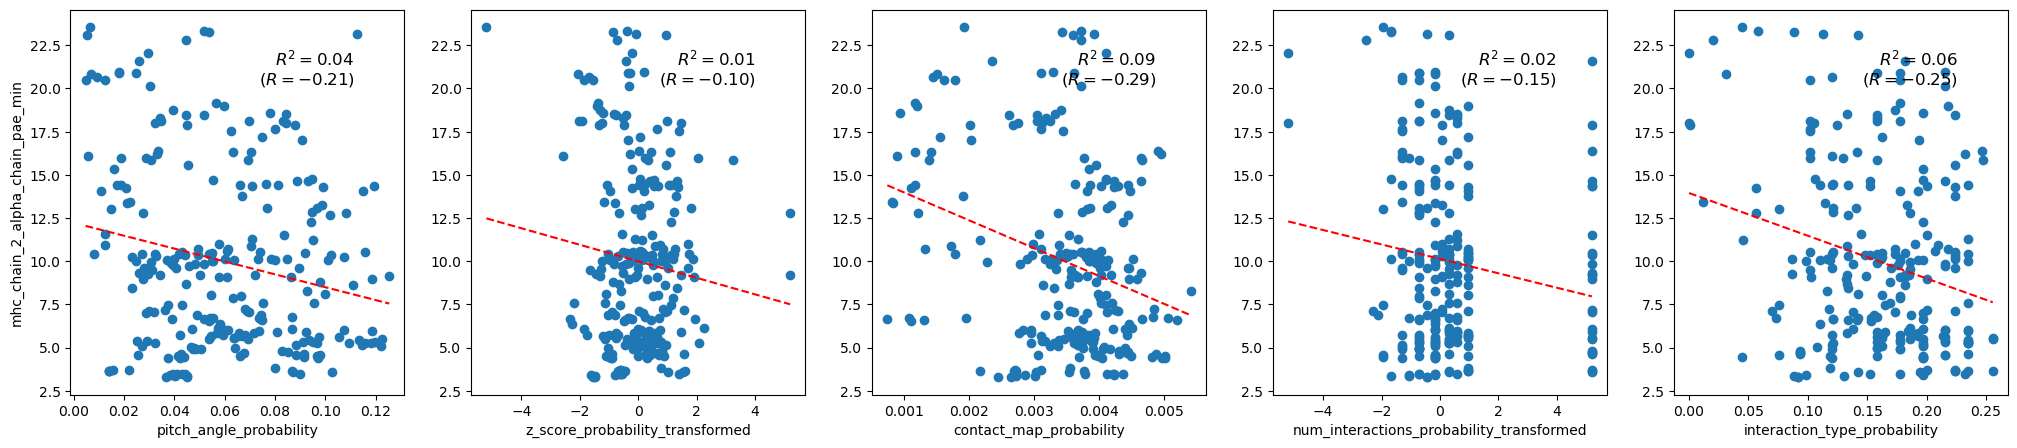

mhc_chain_2_antigen_chain_pae_min
Pearson's correlation: 0.20
                                    OLS Regression Results                                   
Dep. Variable:     mhc_chain_2_antigen_chain_pae_min   R-squared:                       0.040
Model:                                           OLS   Adj. R-squared:                  0.021
Method:                                Least Squares   F-statistic:                     2.048
Date:                               Thu, 03 Jul 2025   Prob (F-statistic):             0.0726
Time:                                       12:11:23   Log-Likelihood:                 2.2917
No. Observations:                                250   AIC:                             7.417
Df Residuals:                                    244   BIC:                             28.55
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.540350,0.551379,0.979998,0.835971,False
z_score_probability_transformed,-0.023990,0.014619,-1.641012,0.051042,False
contact_map_probability,23.952580,16.921801,1.415486,0.920900,False
num_interactions_probability_transformed,-0.018301,0.008605,-2.126781,0.017221,True
interaction_type_probability,-0.053182,0.310640,-0.171201,0.432104,False


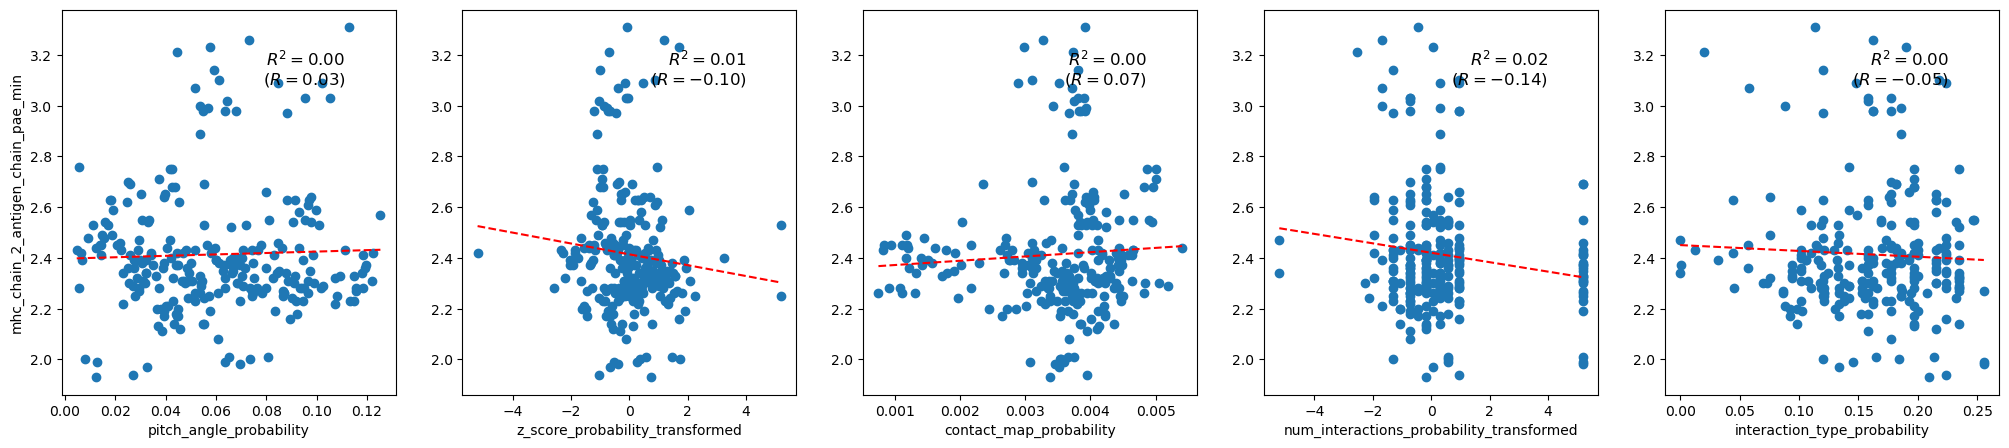

mhc_chain_2_beta_chain_pae_min
Pearson's correlation: 0.37
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain_2_beta_chain_pae_min   R-squared:                       0.138
Model:                                        OLS   Adj. R-squared:                  0.120
Method:                             Least Squares   F-statistic:                     7.789
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):           8.08e-07
Time:                                    12:11:23   Log-Likelihood:                -740.59
No. Observations:                             250   AIC:                             1493.
Df Residuals:                                 244   BIC:                             1514.
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-22.992544,10.763743,-2.136110,0.016833,True
z_score_probability_transformed,0.020203,0.285390,0.070791,0.528189,False
contact_map_probability,-1146.842956,330.338906,-3.471716,0.000306,True
num_interactions_probability_transformed,-0.146191,0.167983,-0.870274,0.192503,False
interaction_type_probability,-16.671347,6.064153,-2.749163,0.003211,True


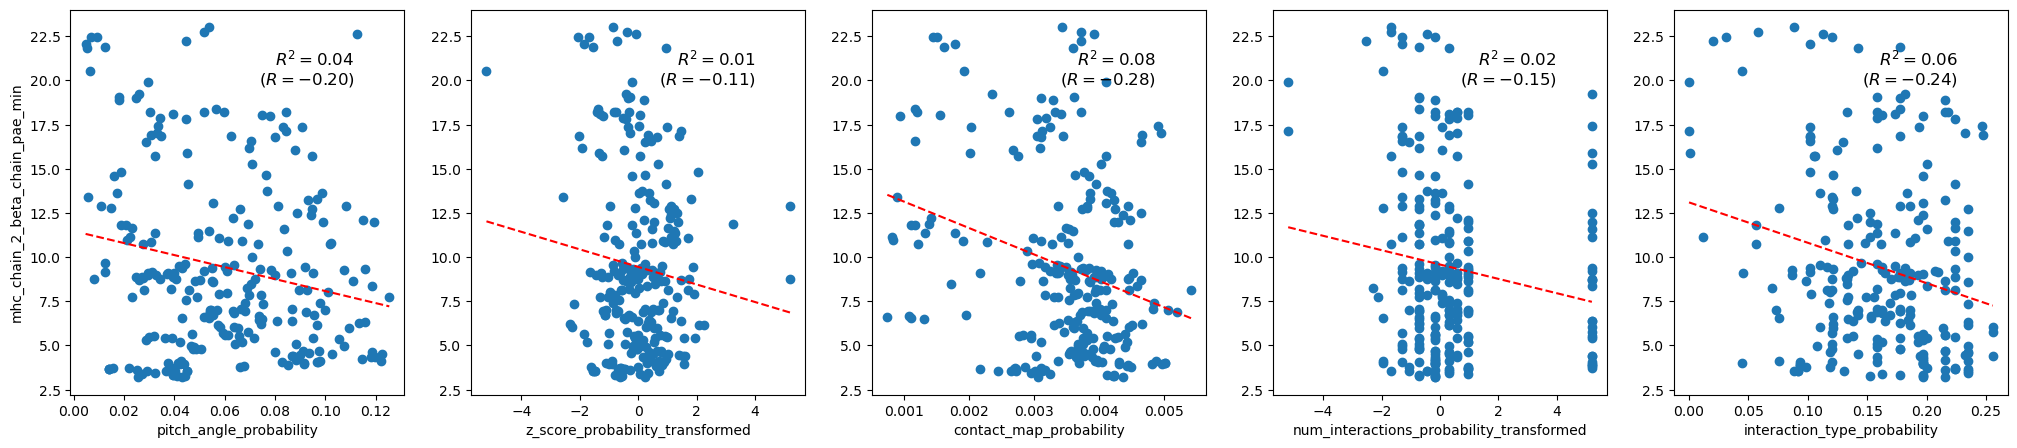

mhc_chain_2_mhc_chain_1_pae_min
Pearson's correlation: 0.30
                                   OLS Regression Results                                  
Dep. Variable:     mhc_chain_2_mhc_chain_1_pae_min   R-squared:                       0.088
Model:                                         OLS   Adj. R-squared:                  0.070
Method:                              Least Squares   F-statistic:                     4.730
Date:                             Thu, 03 Jul 2025   Prob (F-statistic):           0.000384
Time:                                     12:11:24   Log-Likelihood:                 393.31
No. Observations:                              250   AIC:                            -774.6
Df Residuals:                                  244   BIC:                            -753.5
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.232339,0.115392,2.013474,0.977419,False
z_score_probability_transformed,-0.004506,0.003059,-1.472701,0.071060,False
contact_map_probability,-12.346356,3.541377,-3.486315,0.000290,True
num_interactions_probability_transformed,-0.003957,0.001801,-2.197357,0.014468,True
interaction_type_probability,0.034146,0.065010,0.525232,0.700051,False


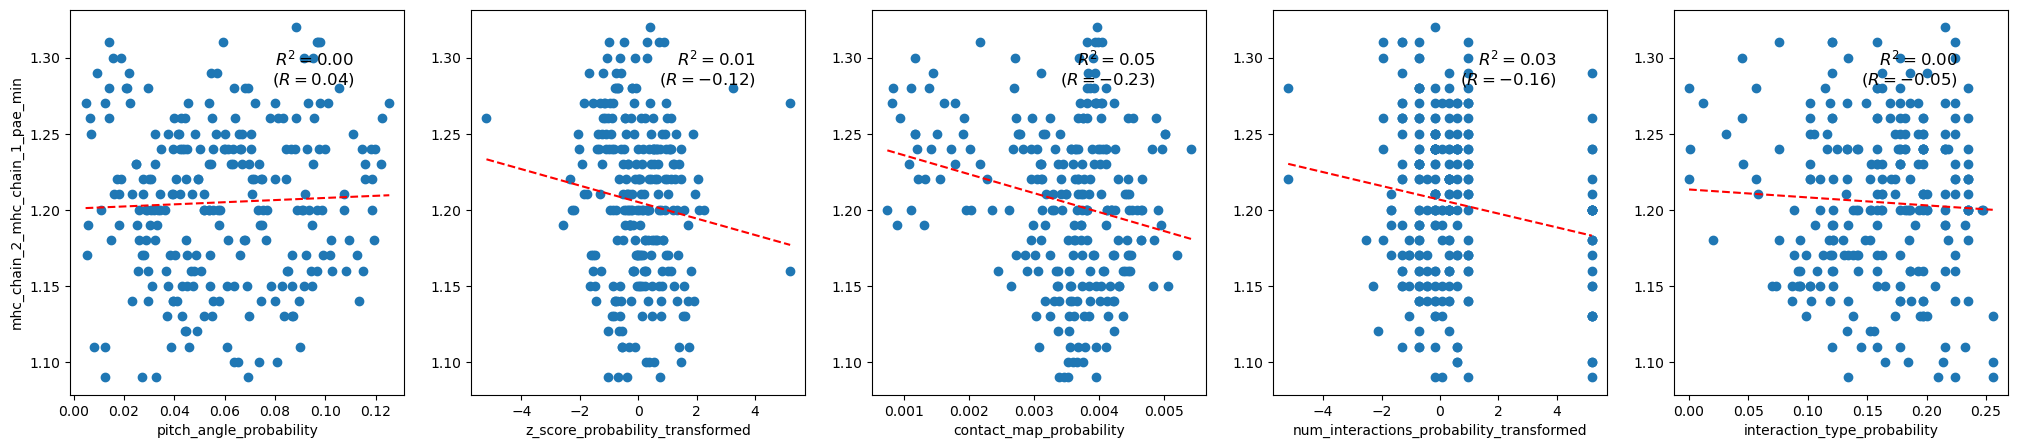

Skipping mhc_chain_2_mhc_chain_2_pae_min
tcr_pmhc_pae_score
Pearson's correlation: 0.39
                            OLS Regression Results                            
Dep. Variable:     tcr_pmhc_pae_score   R-squared:                       0.150
Model:                            OLS   Adj. R-squared:                  0.133
Method:                 Least Squares   F-statistic:                     8.626
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           1.52e-07
Time:                        12:11:24   Log-Likelihood:                -648.13
No. Observations:                 250   AIC:                             1308.
Df Residuals:                     244   BIC:                             1329.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-22.778042,7.436056,-3.063189,0.001218,True
z_score_probability_transformed,0.132571,0.197159,0.672405,0.749019,False
contact_map_probability,-905.197315,228.212295,-3.966470,0.000048,True
num_interactions_probability_transformed,-0.009608,0.116050,-0.082788,0.467044,False
interaction_type_probability,-10.099020,4.189377,-2.410626,0.008333,True


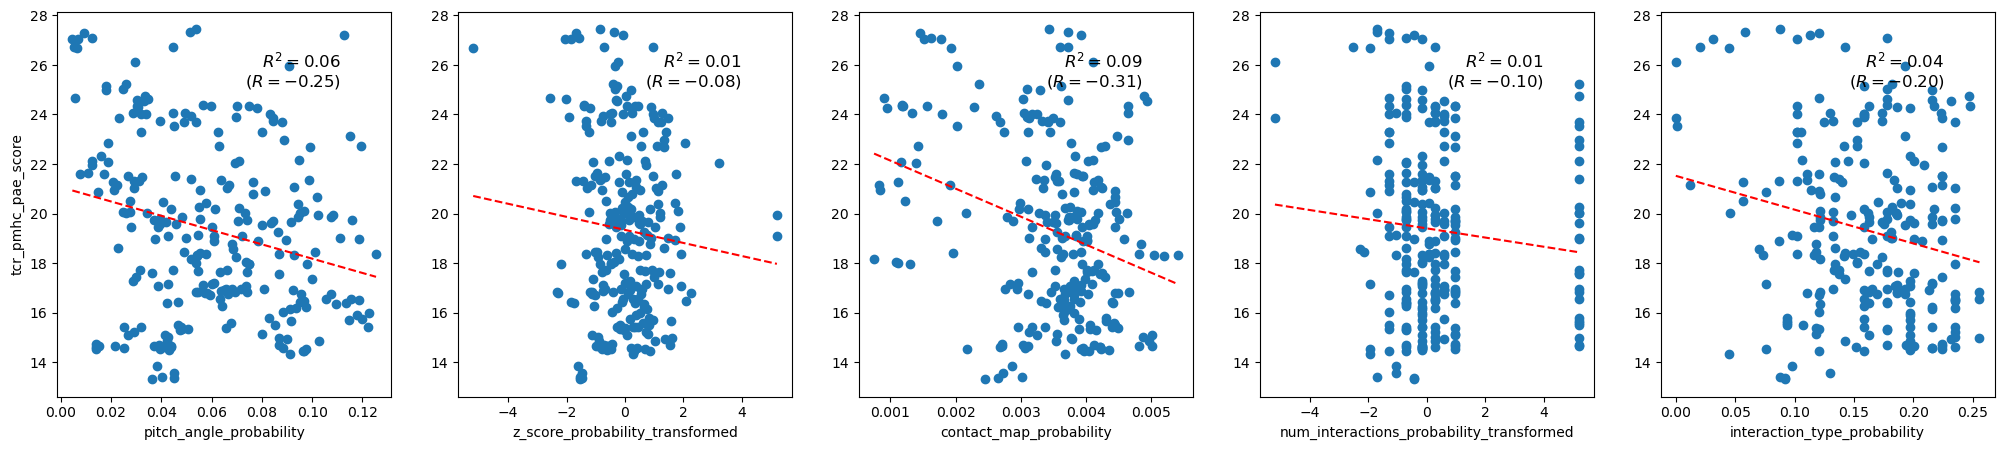

Best results: cdr_pmhc_pae_score R^2: 0.18219886260174156


In [39]:
pae_confidence_columns = sorted(structure_scores.filter(regex='pae').columns.tolist())

best_r_squared = 0
best_reg = None
best_name = None

X = structure_scores[structure_probability_names]
X = sm.add_constant(X)

for confidence_column in pae_confidence_columns:
    y = structure_scores[confidence_column]

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    print(confidence_column)
    print('==============================================================================================')
    print(f"Pearson's correlation: {corr_coef:.2f}")
    print(reg.summary())
    print('\n\n')

    r_squared = reg.rsquared

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    display(coefficients)

    fig, axes = plt.subplots(1, len(structure_probability_names), figsize=(5 * len(structure_probability_names), 5))

    axes[0].set_ylabel(confidence_column)
    for i, column in enumerate(structure_probability_names):
        x = structure_scores[column]
        axes[i].plot(x, y, 'o')

        reg = scipy.stats.linregress(x, y)
        x = np.linspace(x.min(), x.max())
        y_pred = reg.slope * x + reg.intercept

        axes[i].plot(x, y_pred, 'r--')
        axes[i].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

        axes[i].set_xlabel(column)

    plt.show()

    if r_squared > best_r_squared:
        best_r_squared = r_squared
        best_reg = reg
        best_name = confidence_column


print('==============================================================================================')
print('Best results:', best_name, 'R^2:', best_r_squared)
print('==============================================================================================')

alpha_chain_beta_chain_iptm
Pearson's correlation: 0.38
                                 OLS Regression Results                                
Dep. Variable:     alpha_chain_beta_chain_iptm   R-squared:                       0.141
Model:                                     OLS   Adj. R-squared:                  0.124
Method:                          Least Squares   F-statistic:                     8.023
Date:                         Thu, 03 Jul 2025   Prob (F-statistic):           5.07e-07
Time:                                 12:11:25   Log-Likelihood:                 777.85
No. Observations:                          250   AIC:                            -1544.
Df Residuals:                              244   BIC:                            -1523.
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.062525,0.024784,2.522809,0.006139,True
z_score_probability_transformed,-0.001333,0.000657,-2.029242,0.978240,False
contact_map_probability,0.202534,0.760613,0.266277,0.395125,False
num_interactions_probability_transformed,0.000314,0.000387,0.810814,0.209131,False
interaction_type_probability,-0.075861,0.013963,-5.433043,1.000000,False


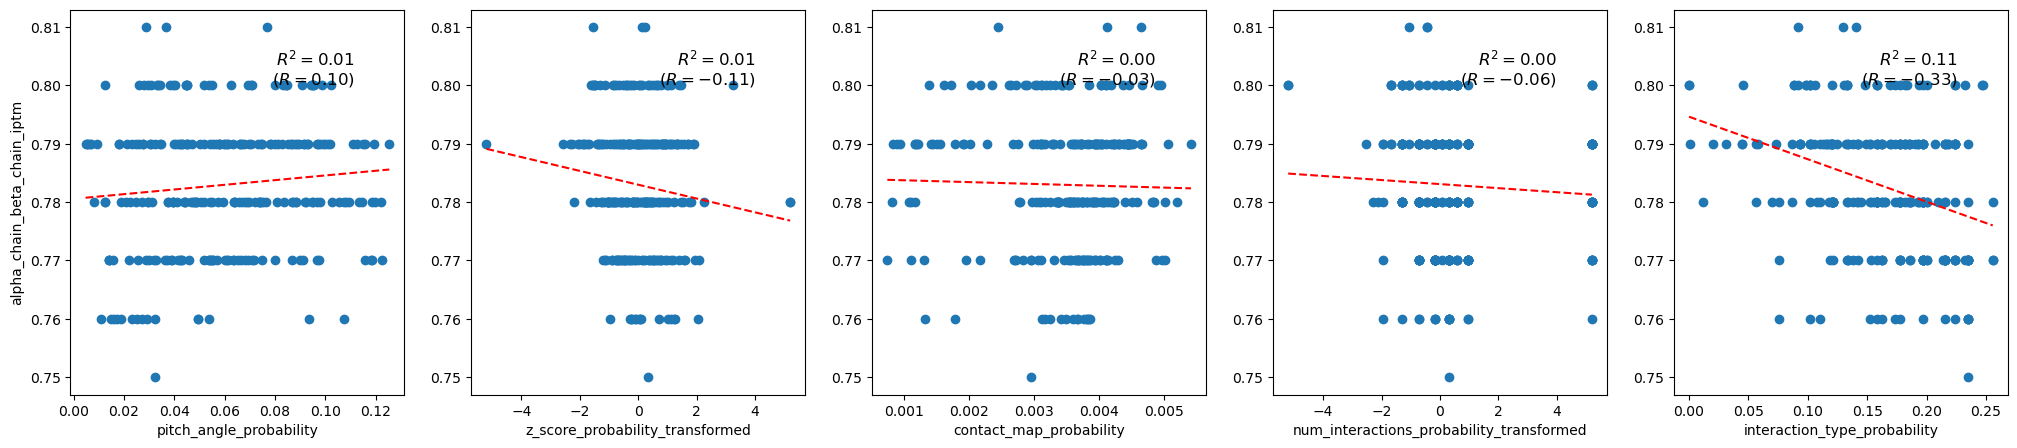

alpha_chain_iptm
Pearson's correlation: 0.37
                            OLS Regression Results                            
Dep. Variable:       alpha_chain_iptm   R-squared:                       0.134
Model:                            OLS   Adj. R-squared:                  0.117
Method:                 Least Squares   F-statistic:                     7.574
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           1.24e-06
Time:                        12:11:26   Log-Likelihood:                 181.80
No. Observations:                 250   AIC:                            -351.6
Df Residuals:                     244   BIC:                            -330.5
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.797468,0.268913,2.965518,0.001661,True
z_score_probability_transformed,-0.010333,0.007130,-1.449239,0.925723,False
contact_map_probability,30.332139,8.252943,3.675312,0.000146,True
num_interactions_probability_transformed,0.000642,0.004197,0.152961,0.439278,False
interaction_type_probability,0.364419,0.151502,2.405368,0.008451,True


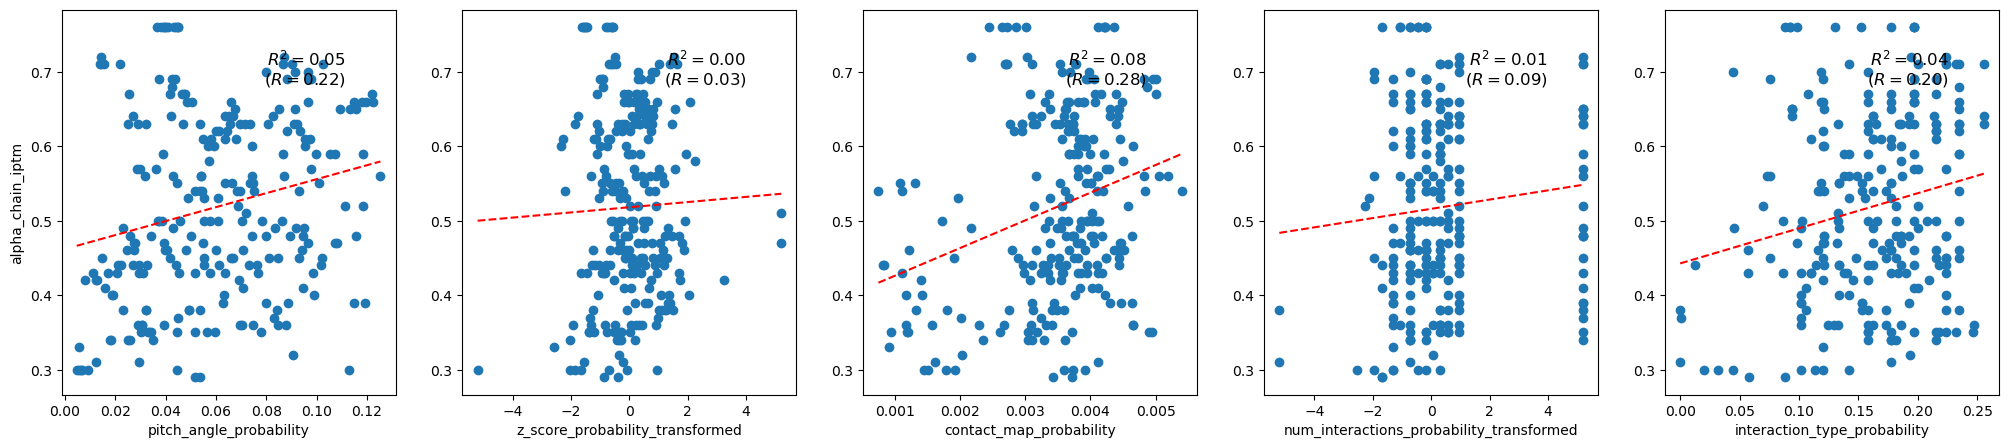

alpha_chain_ptm
Pearson's correlation: 0.30
                            OLS Regression Results                            
Dep. Variable:        alpha_chain_ptm   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.071
Method:                 Least Squares   F-statistic:                     4.812
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           0.000325
Time:                        12:11:26   Log-Likelihood:                 696.62
No. Observations:                 250   AIC:                            -1381.
Df Residuals:                     244   BIC:                            -1360.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.031861,0.034299,-0.928921,0.823076,False
z_score_probability_transformed,-0.002593,0.000909,-2.850998,0.997634,False
contact_map_probability,0.264862,1.052645,0.251615,0.400775,False
num_interactions_probability_transformed,-0.000364,0.000535,-0.679443,0.751250,False
interaction_type_probability,-0.048506,0.019324,-2.510165,0.993642,False


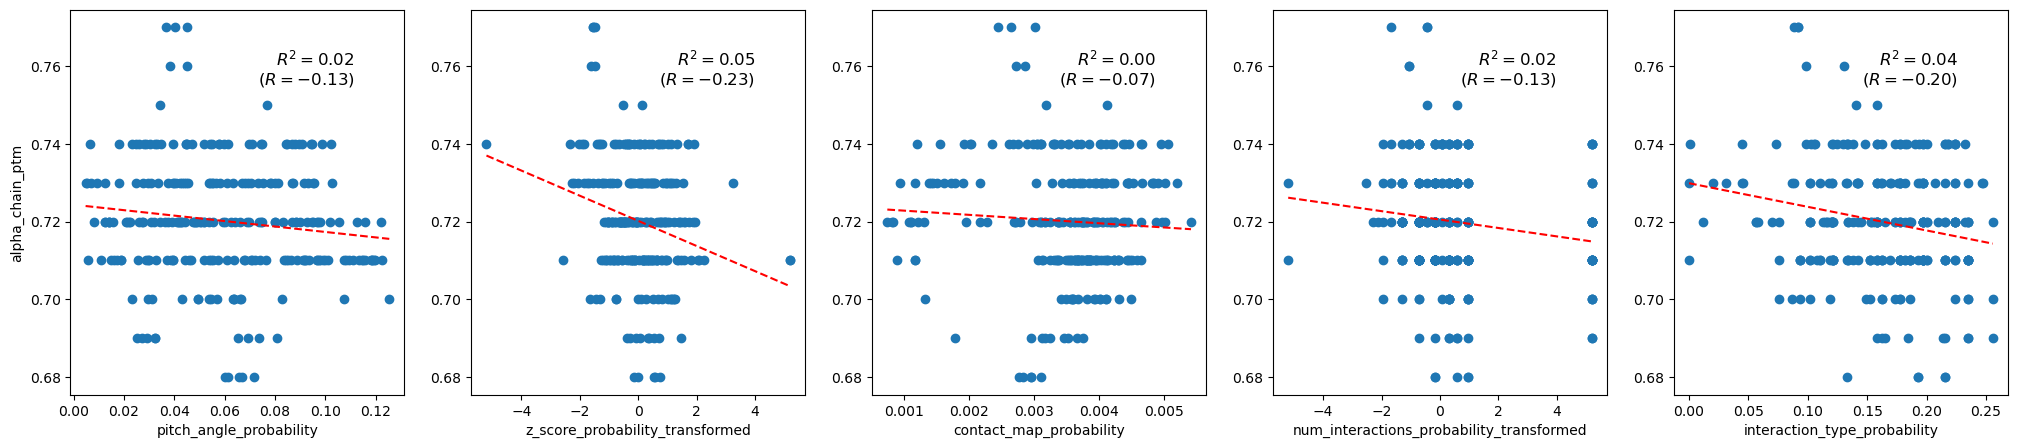

antigen_chain_alpha_chain_iptm
Pearson's correlation: 0.37
                                  OLS Regression Results                                  
Dep. Variable:     antigen_chain_alpha_chain_iptm   R-squared:                       0.138
Model:                                        OLS   Adj. R-squared:                  0.120
Method:                             Least Squares   F-statistic:                     7.794
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):           7.99e-07
Time:                                    12:11:27   Log-Likelihood:                 69.041
No. Observations:                             250   AIC:                            -126.1
Df Residuals:                                 244   BIC:                            -105.0
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,1.117542,0.422178,2.647089,0.004324,True
z_score_probability_transformed,-0.013422,0.011194,-1.199067,0.884167,False
contact_map_probability,47.245829,12.956616,3.646464,0.000162,True
num_interactions_probability_transformed,0.002801,0.006589,0.425067,0.335581,False
interaction_type_probability,0.650385,0.237849,2.734439,0.003353,True


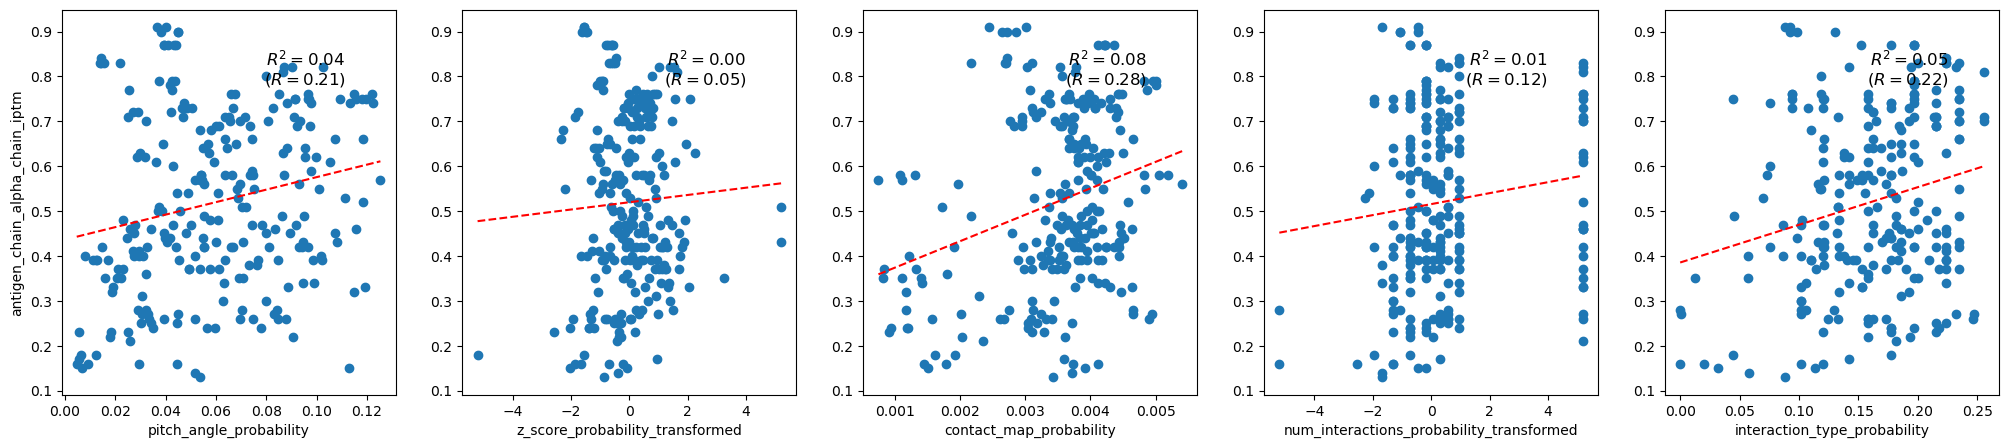

antigen_chain_beta_chain_iptm
Pearson's correlation: 0.37
                                  OLS Regression Results                                 
Dep. Variable:     antigen_chain_beta_chain_iptm   R-squared:                       0.134
Model:                                       OLS   Adj. R-squared:                  0.116
Method:                            Least Squares   F-statistic:                     7.555
Date:                           Thu, 03 Jul 2025   Prob (F-statistic):           1.29e-06
Time:                                   12:11:28   Log-Likelihood:                 66.388
No. Observations:                            250   AIC:                            -120.8
Df Residuals:                                244   BIC:                            -99.65
Df Model:                                      5                                         
Covariance Type:                       nonrobust                                         
                                          

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,1.113905,0.426681,2.610630,0.004798,True
z_score_probability_transformed,-0.009828,0.011313,-0.868715,0.807072,False
contact_map_probability,43.384892,13.094814,3.313135,0.000531,True
num_interactions_probability_transformed,0.002009,0.006659,0.301661,0.381584,False
interaction_type_probability,0.720381,0.240386,2.996764,0.001505,True


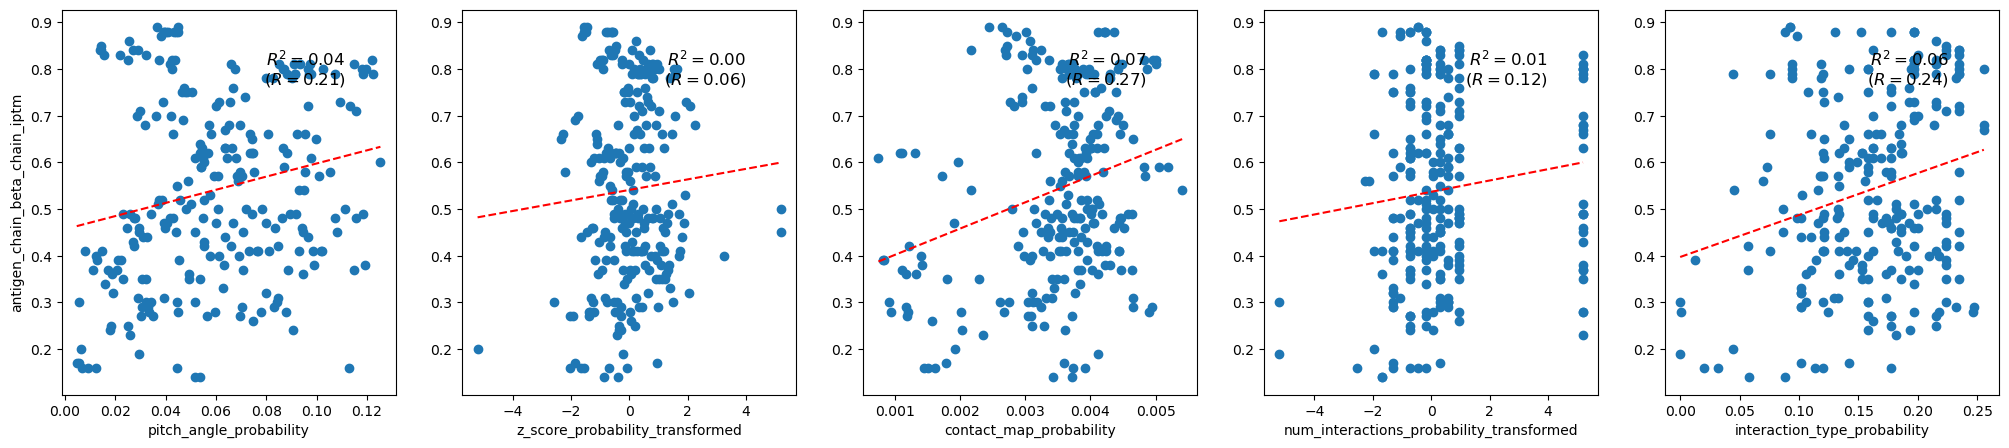

antigen_chain_iptm
Pearson's correlation: 0.32
                            OLS Regression Results                            
Dep. Variable:     antigen_chain_iptm   R-squared:                       0.101
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     5.510
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           7.94e-05
Time:                        12:11:28   Log-Likelihood:                 221.01
No. Observations:                 250   AIC:                            -430.0
Df Residuals:                     244   BIC:                            -408.9
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.454002,0.229877,1.974972,0.024699,True
z_score_probability_transformed,-0.005259,0.006095,-0.862849,0.805466,False
contact_map_probability,18.107891,7.054932,2.566699,0.005432,True
num_interactions_probability_transformed,0.002808,0.003588,0.782582,0.217316,False
interaction_type_probability,0.359950,0.129510,2.779326,0.002936,True


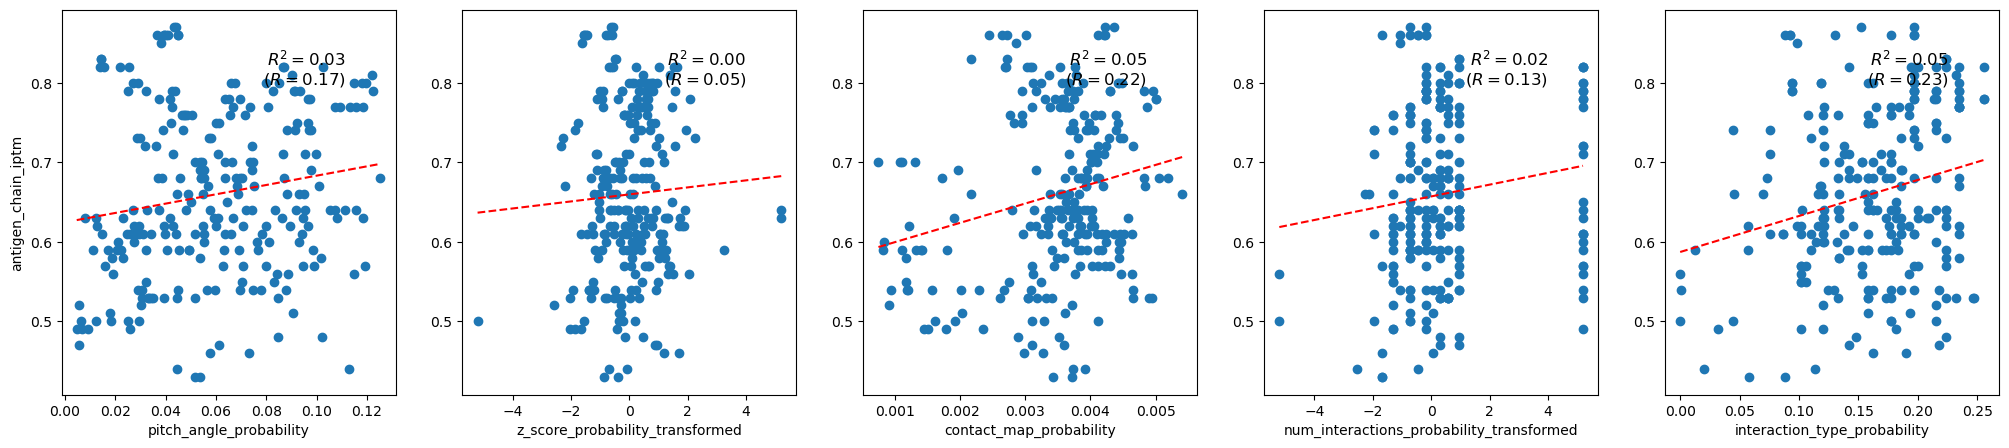

antigen_chain_ptm
Pearson's correlation: 0.33
                            OLS Regression Results                            
Dep. Variable:      antigen_chain_ptm   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                  0.093
Method:                 Least Squares   F-statistic:                     6.103
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           2.40e-05
Time:                        12:11:29   Log-Likelihood:                 1004.8
No. Observations:                 250   AIC:                            -1998.
Df Residuals:                     244   BIC:                            -1976.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.000172,0.010000,-0.017206,0.506857,False
z_score_probability_transformed,-0.000595,0.000265,-2.245076,0.987170,False
contact_map_probability,-1.183406,0.306900,-3.855995,0.999926,False
num_interactions_probability_transformed,-0.000243,0.000156,-1.555986,0.939496,False
interaction_type_probability,0.002140,0.005634,0.379917,0.352169,False


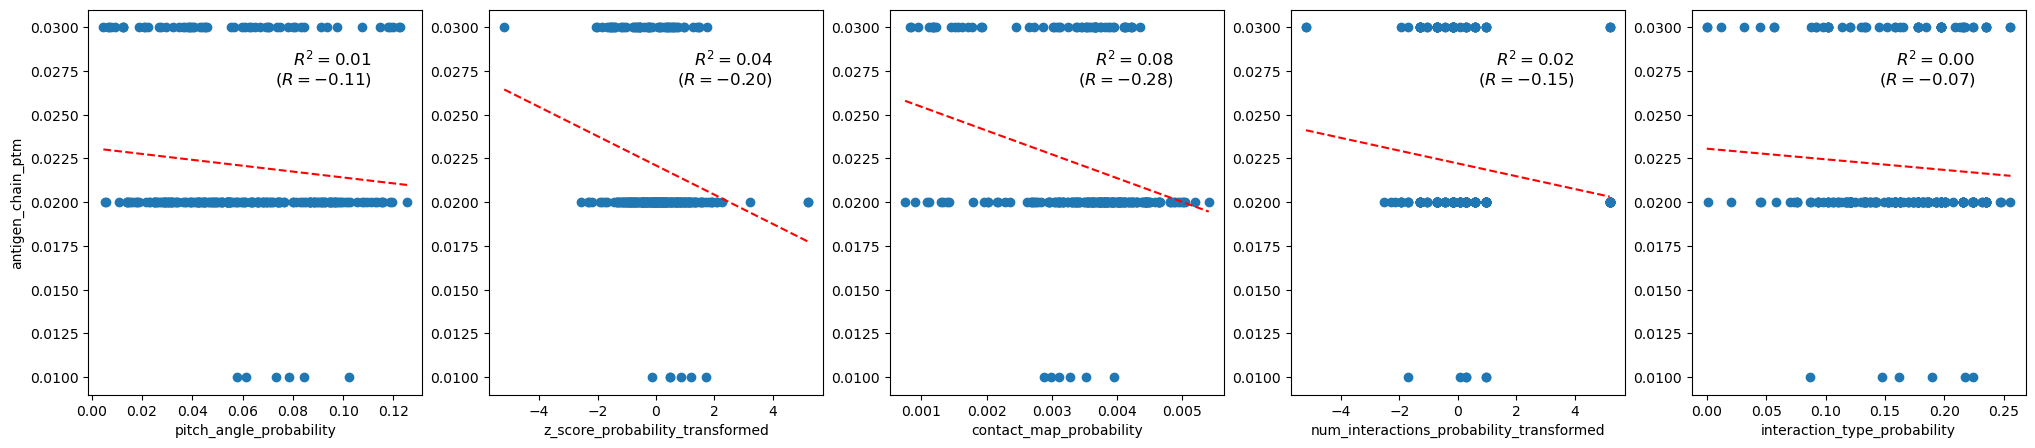

beta_chain_iptm
Pearson's correlation: 0.36
                            OLS Regression Results                            
Dep. Variable:        beta_chain_iptm   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     7.461
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           1.56e-06
Time:                        12:11:30   Log-Likelihood:                 178.60
No. Observations:                 250   AIC:                            -345.2
Df Residuals:                     244   BIC:                            -324.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.752873,0.272379,2.764064,0.003072,True
z_score_probability_transformed,-0.008417,0.007222,-1.165449,0.877512,False
contact_map_probability,30.135648,8.359298,3.605045,0.000189,True
num_interactions_probability_transformed,0.000040,0.004251,0.009359,0.496270,False
interaction_type_probability,0.406700,0.153455,2.650294,0.004284,True


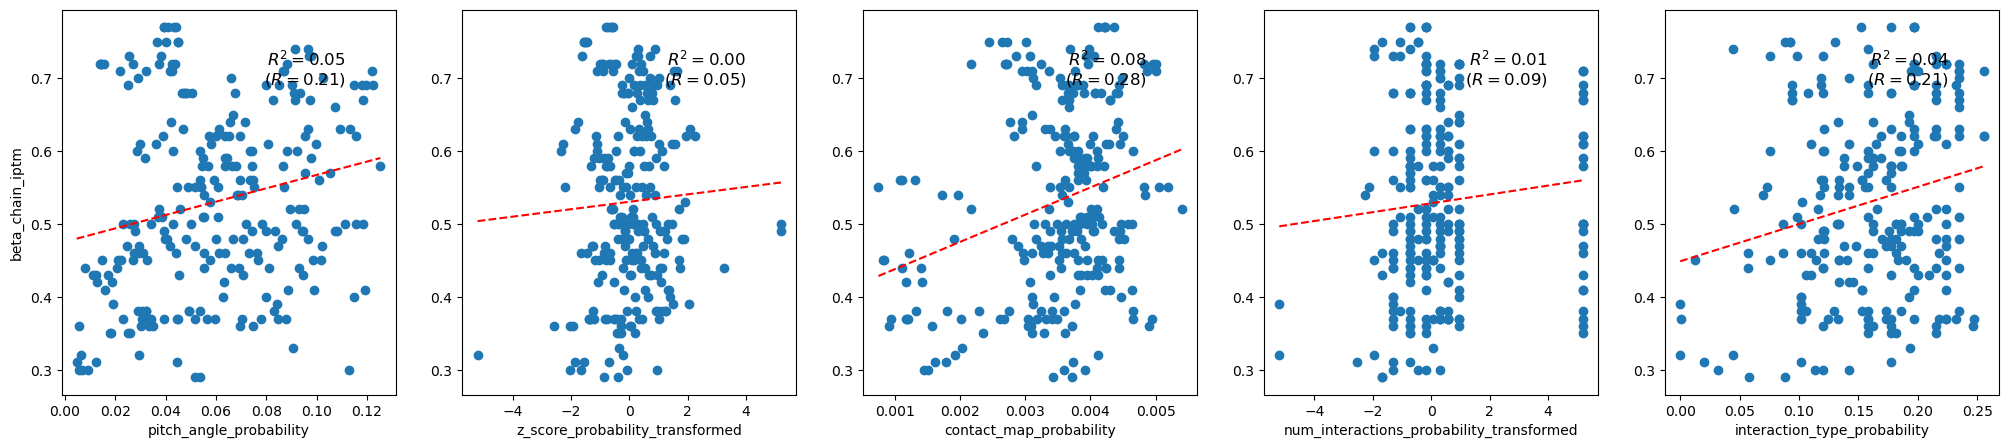

beta_chain_ptm
Pearson's correlation: 0.37
                            OLS Regression Results                            
Dep. Variable:         beta_chain_ptm   R-squared:                       0.140
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     7.935
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           6.04e-07
Time:                        12:11:30   Log-Likelihood:                 735.11
No. Observations:                 250   AIC:                            -1458.
Df Residuals:                     244   BIC:                            -1437.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.088830,0.029405,3.020962,0.001394,True
z_score_probability_transformed,-0.000511,0.000780,-0.655549,0.743634,False
contact_map_probability,-2.753909,0.902425,-3.051675,0.998736,False
num_interactions_probability_transformed,-0.000077,0.000459,-0.167266,0.566350,False
interaction_type_probability,-0.068584,0.016566,-4.139999,0.999976,False


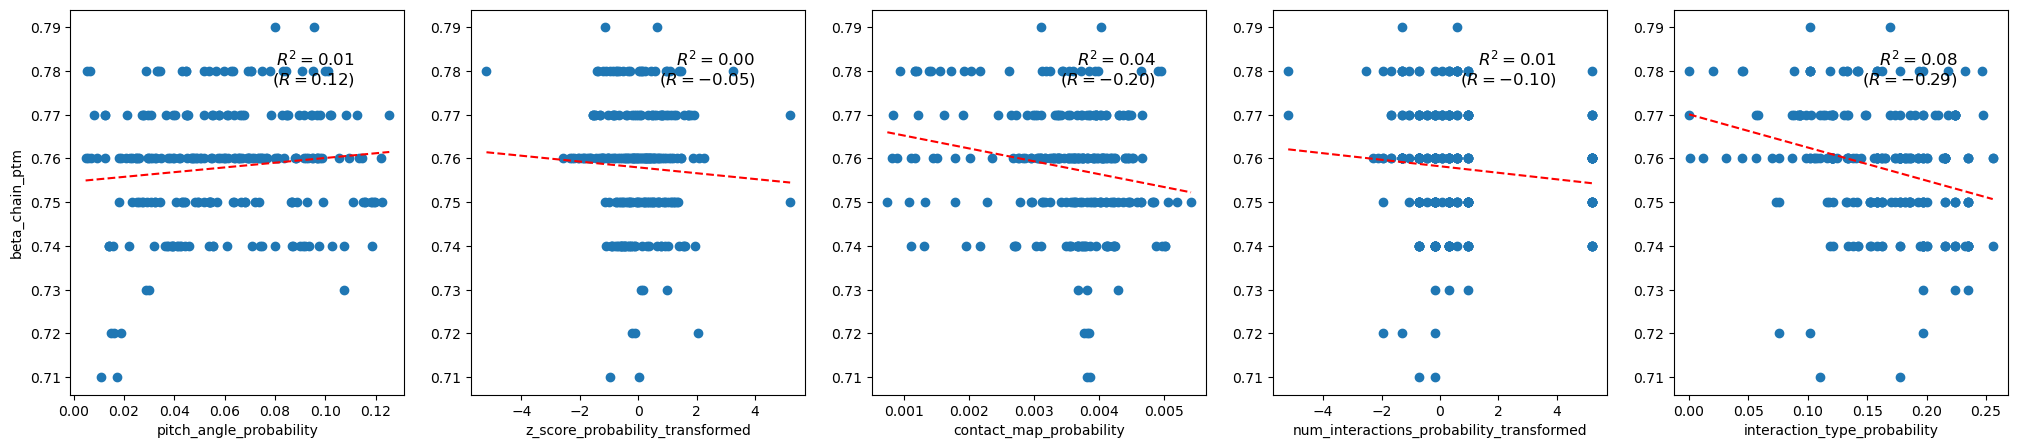

combined_iptm
Pearson's correlation: 0.37
                            OLS Regression Results                            
Dep. Variable:          combined_iptm   R-squared:                       0.136
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     7.694
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           9.77e-07
Time:                        12:11:31   Log-Likelihood:                 78.840
No. Observations:                 250   AIC:                            -145.7
Df Residuals:                     244   BIC:                            -124.6
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,1.166581,0.405949,2.873714,0.002207,True
z_score_probability_transformed,-0.012771,0.010763,-1.186563,0.881723,False
contact_map_probability,44.790472,12.458555,3.595158,0.000196,True
num_interactions_probability_transformed,0.000886,0.006335,0.139840,0.444451,False
interaction_type_probability,0.605974,0.228706,2.649571,0.004293,True


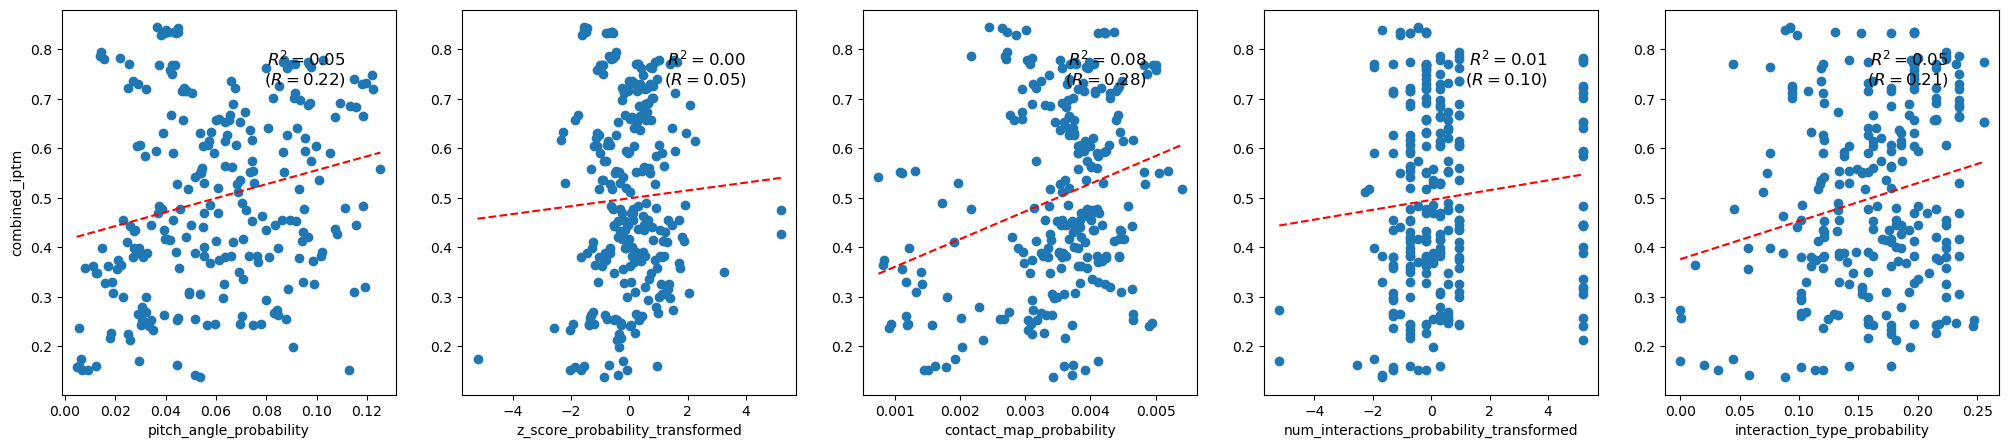

iptm
Pearson's correlation: 0.38
                            OLS Regression Results                            
Dep. Variable:                   iptm   R-squared:                       0.145
Model:                            OLS   Adj. R-squared:                  0.128
Method:                 Least Squares   F-statistic:                     8.301
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           2.91e-07
Time:                        12:11:31   Log-Likelihood:                 240.91
No. Observations:                 250   AIC:                            -469.8
Df Residuals:                     244   BIC:                            -448.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.670557,0.212290,3.158688,0.000892,True
z_score_probability_transformed,-0.007398,0.005629,-1.314351,0.905019,False
contact_map_probability,25.487217,6.515168,3.911982,0.000059,True
num_interactions_probability_transformed,-0.000105,0.003313,-0.031769,0.512659,False
interaction_type_probability,0.288456,0.119601,2.411816,0.008306,True


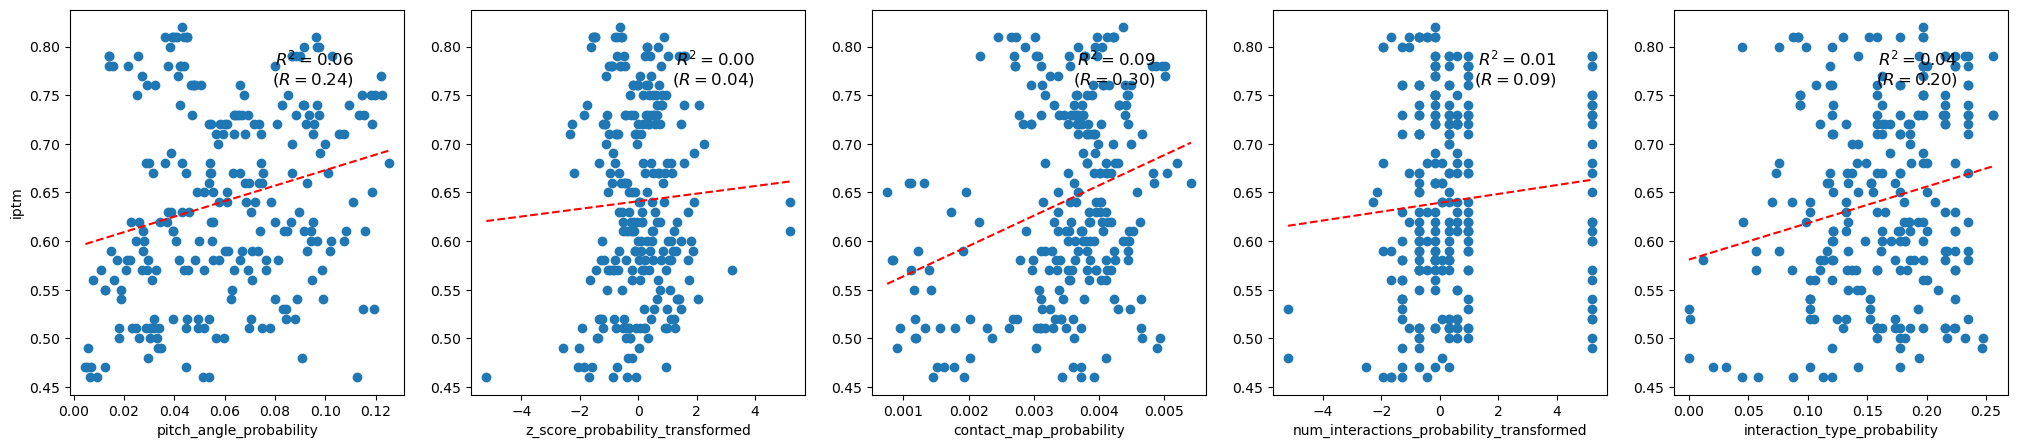

mhc_chain_1_alpha_chain_iptm
Pearson's correlation: 0.37
                                 OLS Regression Results                                 
Dep. Variable:     mhc_chain_1_alpha_chain_iptm   R-squared:                       0.138
Model:                                      OLS   Adj. R-squared:                  0.120
Method:                           Least Squares   F-statistic:                     7.802
Date:                          Thu, 03 Jul 2025   Prob (F-statistic):           7.88e-07
Time:                                  12:11:32   Log-Likelihood:                 86.152
No. Observations:                           250   AIC:                            -160.3
Df Residuals:                               244   BIC:                            -139.2
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,1.278533,0.394248,3.242970,0.000674,True
z_score_probability_transformed,-0.015375,0.010453,-1.470835,0.928688,False
contact_map_probability,44.942974,12.099447,3.714465,0.000126,True
num_interactions_probability_transformed,-0.000008,0.006153,-0.001263,0.500503,False
interaction_type_probability,0.500887,0.222114,2.255089,0.012507,True


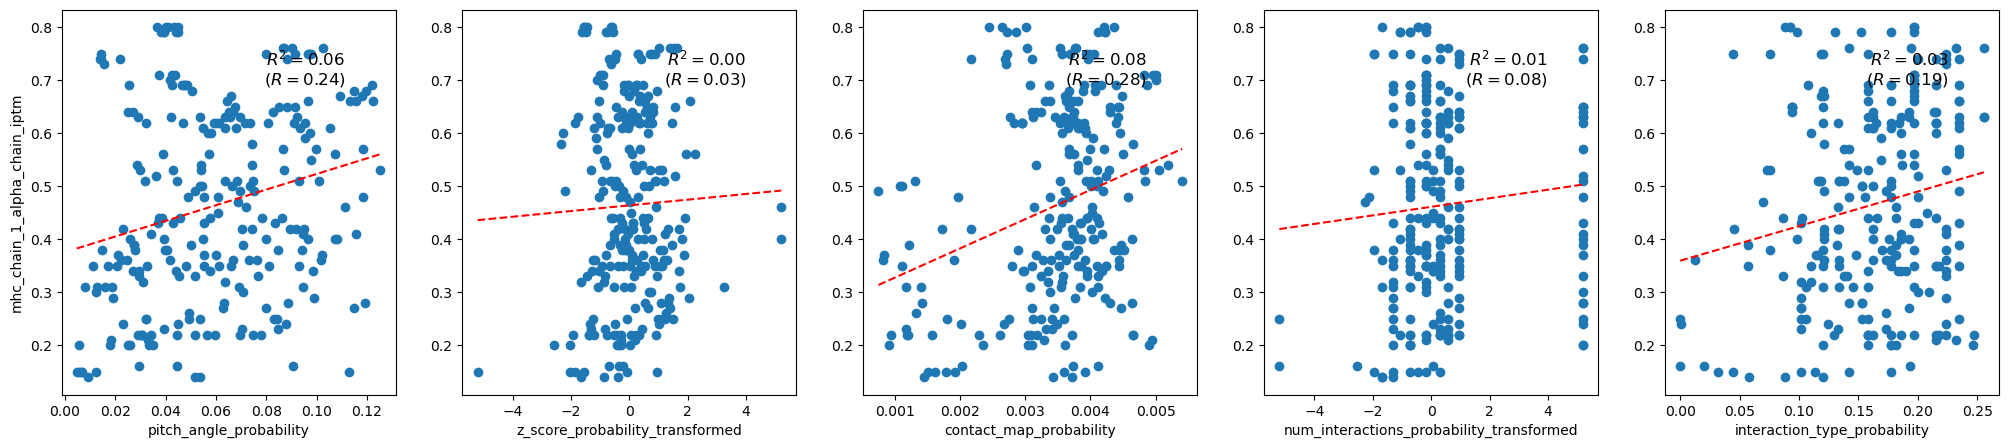

mhc_chain_1_antigen_chain_iptm
Pearson's correlation: 0.23
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain_1_antigen_chain_iptm   R-squared:                       0.053
Model:                                        OLS   Adj. R-squared:                  0.034
Method:                             Least Squares   F-statistic:                     2.741
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):             0.0198
Time:                                    12:11:33   Log-Likelihood:                 417.16
No. Observations:                             250   AIC:                            -822.3
Df Residuals:                                 244   BIC:                            -801.2
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.189736,0.104892,-1.808867,0.964149,False
z_score_probability_transformed,0.000658,0.002781,0.236478,0.406630,False
contact_map_probability,-8.432445,3.219142,-2.619469,0.995321,False
num_interactions_probability_transformed,0.002305,0.001637,1.407841,0.080225,False
interaction_type_probability,0.023044,0.059095,0.389943,0.348459,False


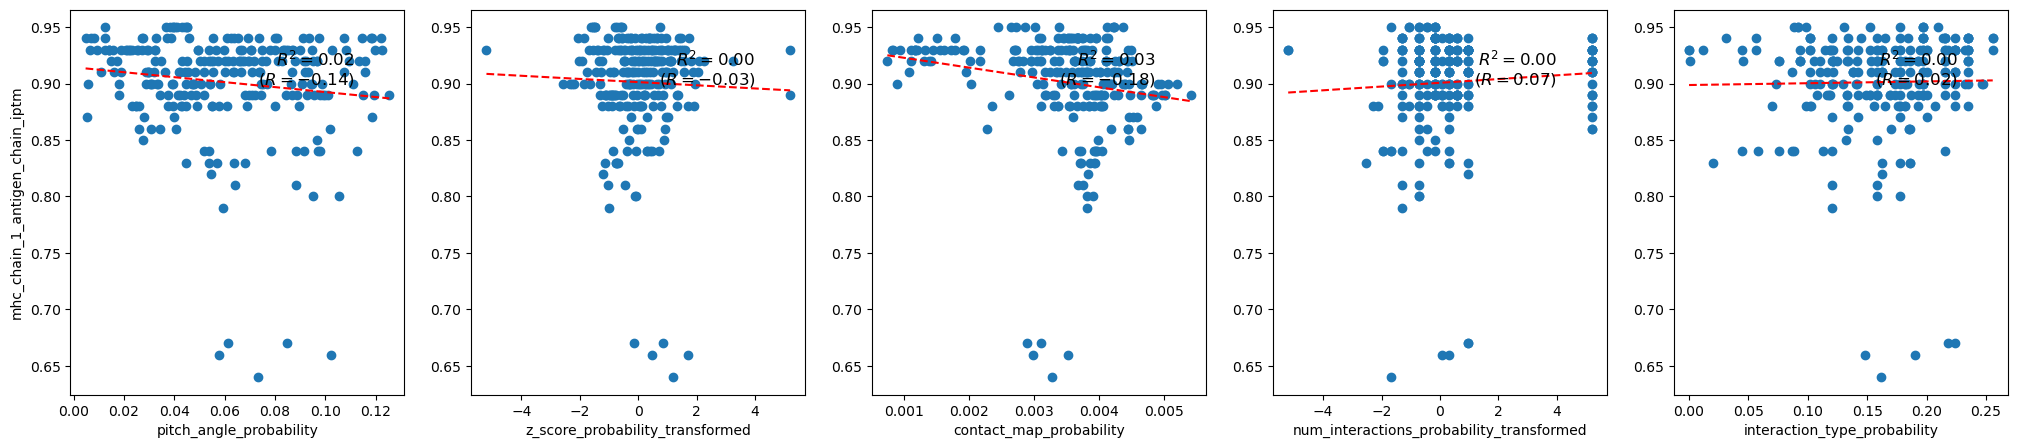

mhc_chain_1_beta_chain_iptm
Pearson's correlation: 0.36
                                 OLS Regression Results                                
Dep. Variable:     mhc_chain_1_beta_chain_iptm   R-squared:                       0.133
Model:                                     OLS   Adj. R-squared:                  0.115
Method:                          Least Squares   F-statistic:                     7.483
Date:                         Thu, 03 Jul 2025   Prob (F-statistic):           1.49e-06
Time:                                 12:11:33   Log-Likelihood:                 88.438
No. Observations:                          250   AIC:                            -164.9
Df Residuals:                              244   BIC:                            -143.7
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,1.156343,0.390659,2.959979,0.001690,True
z_score_probability_transformed,-0.012461,0.010358,-1.203041,0.884937,False
contact_map_probability,43.588194,11.989314,3.635587,0.000169,True
num_interactions_probability_transformed,-0.001258,0.006097,-0.206313,0.581641,False
interaction_type_probability,0.552241,0.220092,2.509137,0.006376,True


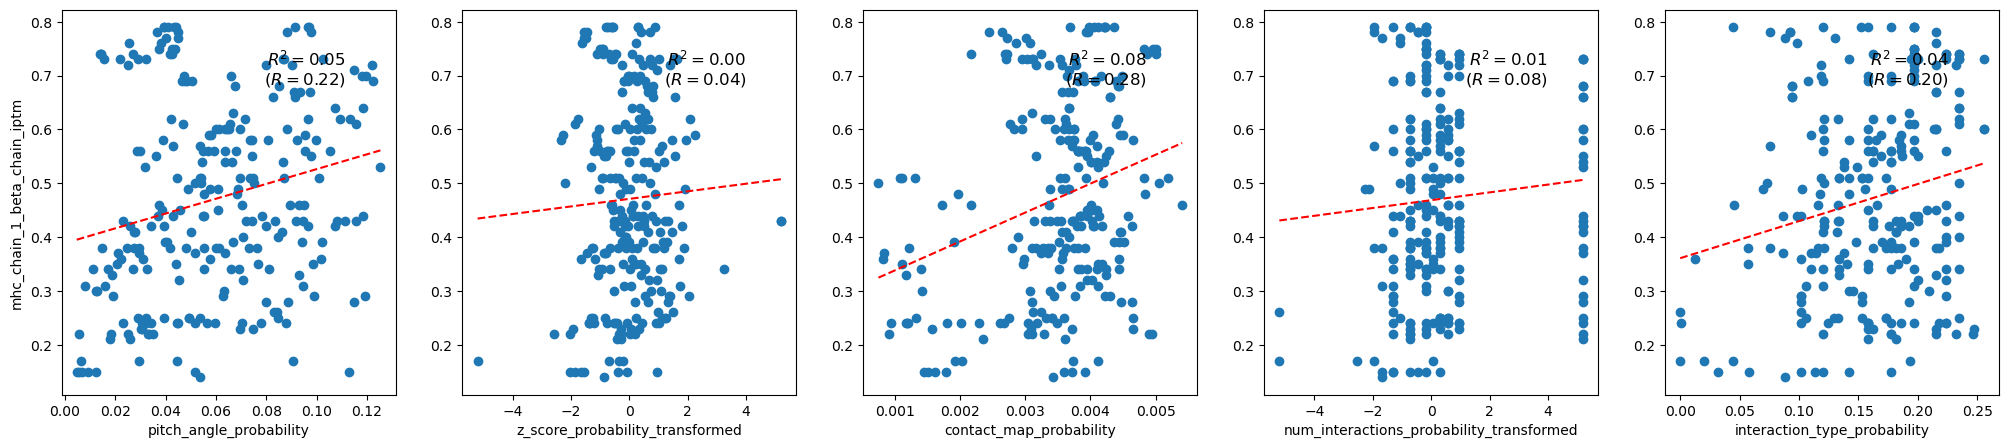

mhc_chain_1_iptm
Pearson's correlation: 0.34
                            OLS Regression Results                            
Dep. Variable:       mhc_chain_1_iptm   R-squared:                       0.116
Model:                            OLS   Adj. R-squared:                  0.098
Method:                 Least Squares   F-statistic:                     6.390
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           1.34e-05
Time:                        12:11:34   Log-Likelihood:                 248.82
No. Observations:                 250   AIC:                            -485.6
Df Residuals:                     244   BIC:                            -464.5
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.523920,0.205675,2.547316,0.005735,True
z_score_probability_transformed,-0.006471,0.005453,-1.186706,0.881751,False
contact_map_probability,21.507436,6.312167,3.407299,0.000384,True
num_interactions_probability_transformed,0.000347,0.003210,0.108100,0.457002,False
interaction_type_probability,0.272027,0.115875,2.347598,0.009847,True


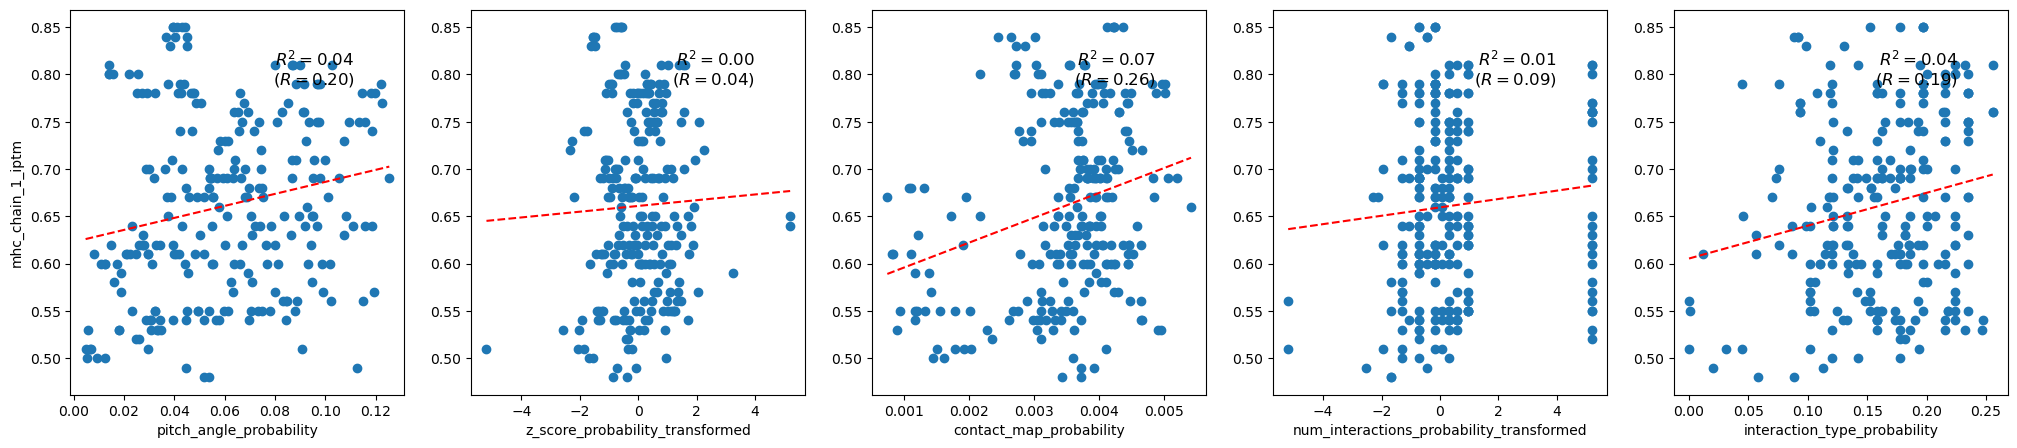

mhc_chain_1_mhc_chain_2_iptm
Pearson's correlation: 0.29
                                 OLS Regression Results                                 
Dep. Variable:     mhc_chain_1_mhc_chain_2_iptm   R-squared:                       0.086
Model:                                      OLS   Adj. R-squared:                  0.067
Method:                           Least Squares   F-statistic:                     4.574
Date:                          Thu, 03 Jul 2025   Prob (F-statistic):           0.000524
Time:                                  12:11:35   Log-Likelihood:                 616.61
No. Observations:                           250   AIC:                            -1221.
Df Residuals:                               244   BIC:                            -1200.
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.136441,0.047236,-2.888517,0.997891,False
z_score_probability_transformed,0.000786,0.001252,0.627641,0.265413,False
contact_map_probability,5.323630,1.449660,3.672330,0.000148,True
num_interactions_probability_transformed,0.000680,0.000737,0.922045,0.178708,False
interaction_type_probability,0.020843,0.026612,0.783208,0.217132,False


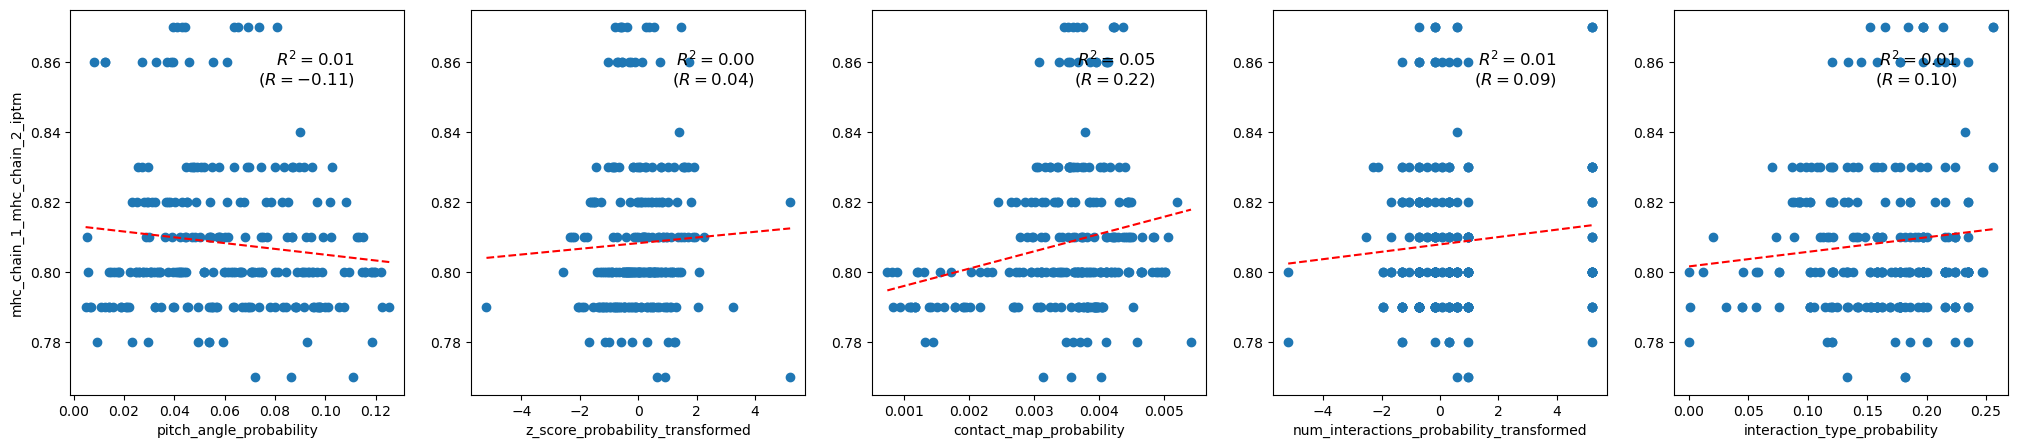

mhc_chain_1_ptm
Pearson's correlation: 0.36
                            OLS Regression Results                            
Dep. Variable:        mhc_chain_1_ptm   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     7.473
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           1.52e-06
Time:                        12:11:35   Log-Likelihood:                 714.74
No. Observations:                 250   AIC:                            -1417.
Df Residuals:                     244   BIC:                            -1396.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.055844,0.031900,-1.750567,9.593613e-01,False
z_score_probability_transformed,0.000126,0.000846,0.149467,4.406544e-01,False
contact_map_probability,5.540569,0.979022,5.659291,2.124692e-08,True
num_interactions_probability_transformed,0.000315,0.000498,0.632648,2.637779e-01,False
interaction_type_probability,0.012235,0.017972,0.680796,2.483229e-01,False


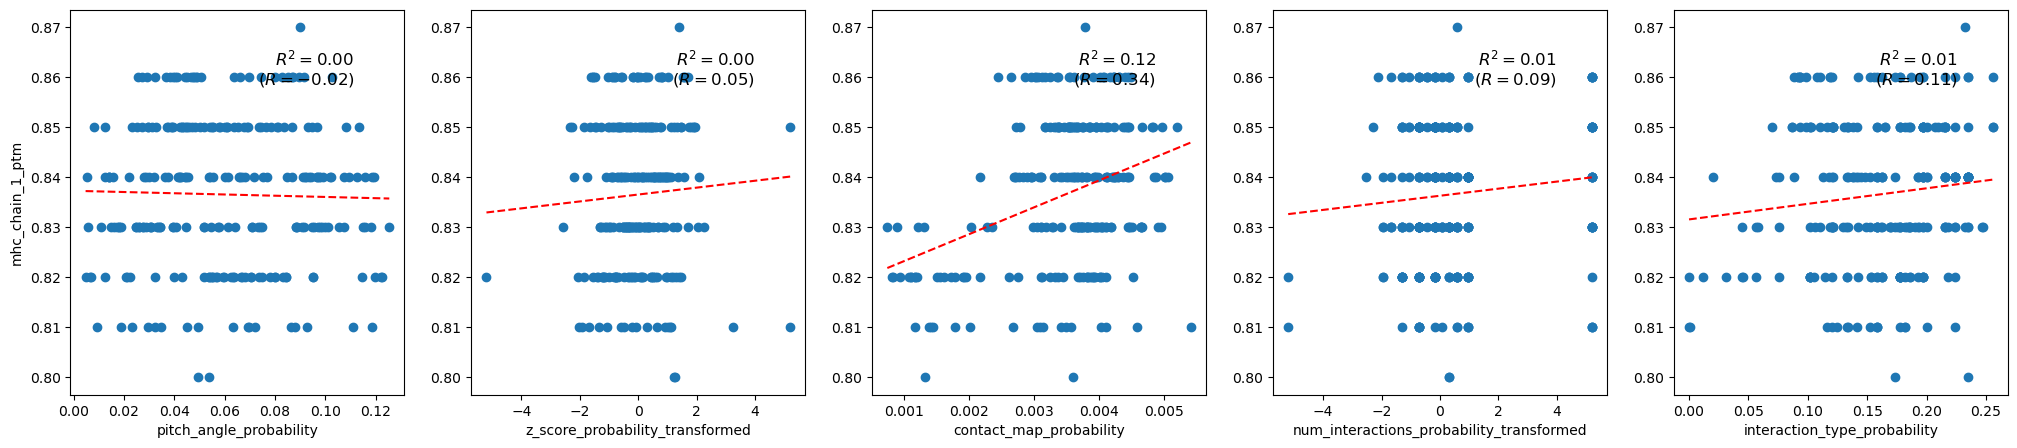

mhc_chain_2_alpha_chain_iptm
Pearson's correlation: 0.35
                                 OLS Regression Results                                 
Dep. Variable:     mhc_chain_2_alpha_chain_iptm   R-squared:                       0.123
Model:                                      OLS   Adj. R-squared:                  0.105
Method:                           Least Squares   F-statistic:                     6.813
Date:                          Thu, 03 Jul 2025   Prob (F-statistic):           5.73e-06
Time:                                  12:11:36   Log-Likelihood:                 179.83
No. Observations:                           250   AIC:                            -347.7
Df Residuals:                               244   BIC:                            -326.5
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.750393,0.271036,2.768607,0.003031,True
z_score_probability_transformed,-0.011912,0.007186,-1.657661,0.950664,False
contact_map_probability,29.253037,8.318094,3.516796,0.000260,True
num_interactions_probability_transformed,-0.000354,0.004230,-0.083682,0.533311,False
interaction_type_probability,0.368822,0.152698,2.415362,0.008228,True


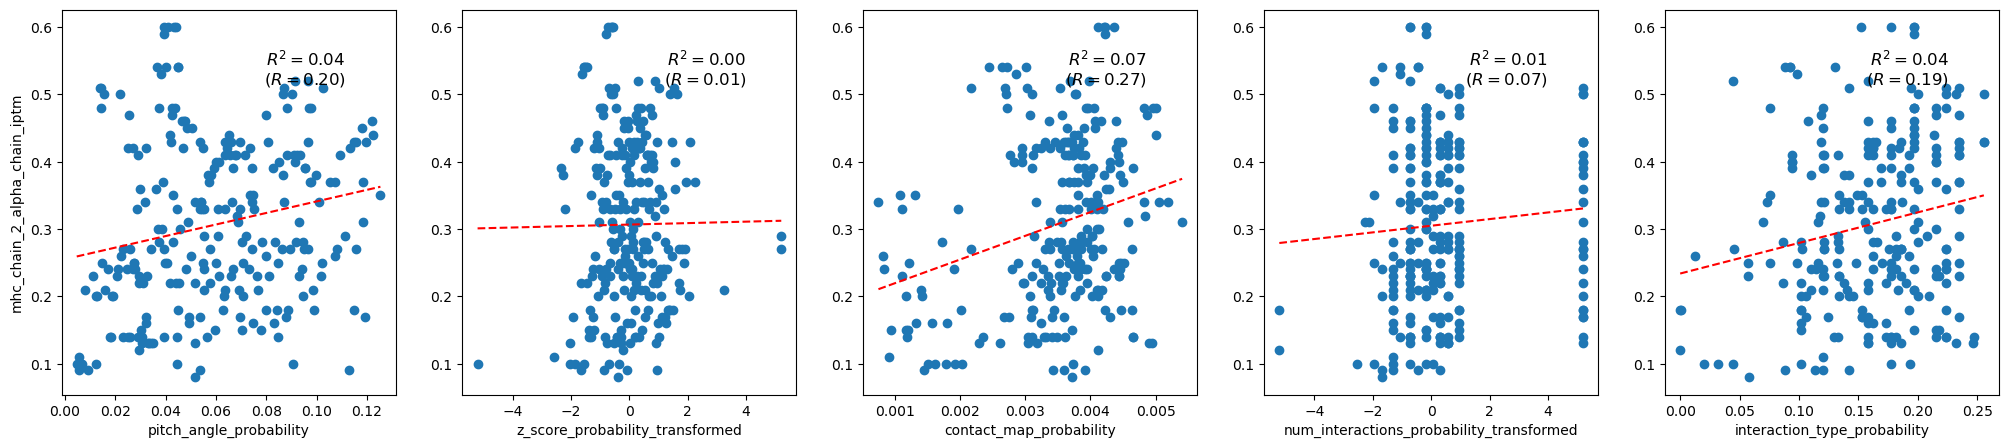

mhc_chain_2_antigen_chain_iptm
Pearson's correlation: 0.23
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain_2_antigen_chain_iptm   R-squared:                       0.055
Model:                                        OLS   Adj. R-squared:                  0.036
Method:                             Least Squares   F-statistic:                     2.844
Date:                            Thu, 03 Jul 2025   Prob (F-statistic):             0.0162
Time:                                    12:11:37   Log-Likelihood:                 375.17
No. Observations:                             250   AIC:                            -738.3
Df Residuals:                                 244   BIC:                            -717.2
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.218947,0.124080,-1.764567,0.960556,False
z_score_probability_transformed,0.000591,0.003290,0.179531,0.428835,False
contact_map_probability,-9.330321,3.808005,-2.450186,0.992509,False
num_interactions_probability_transformed,0.003600,0.001936,1.858949,0.032119,True
interaction_type_probability,0.045988,0.069905,0.657860,0.255624,False


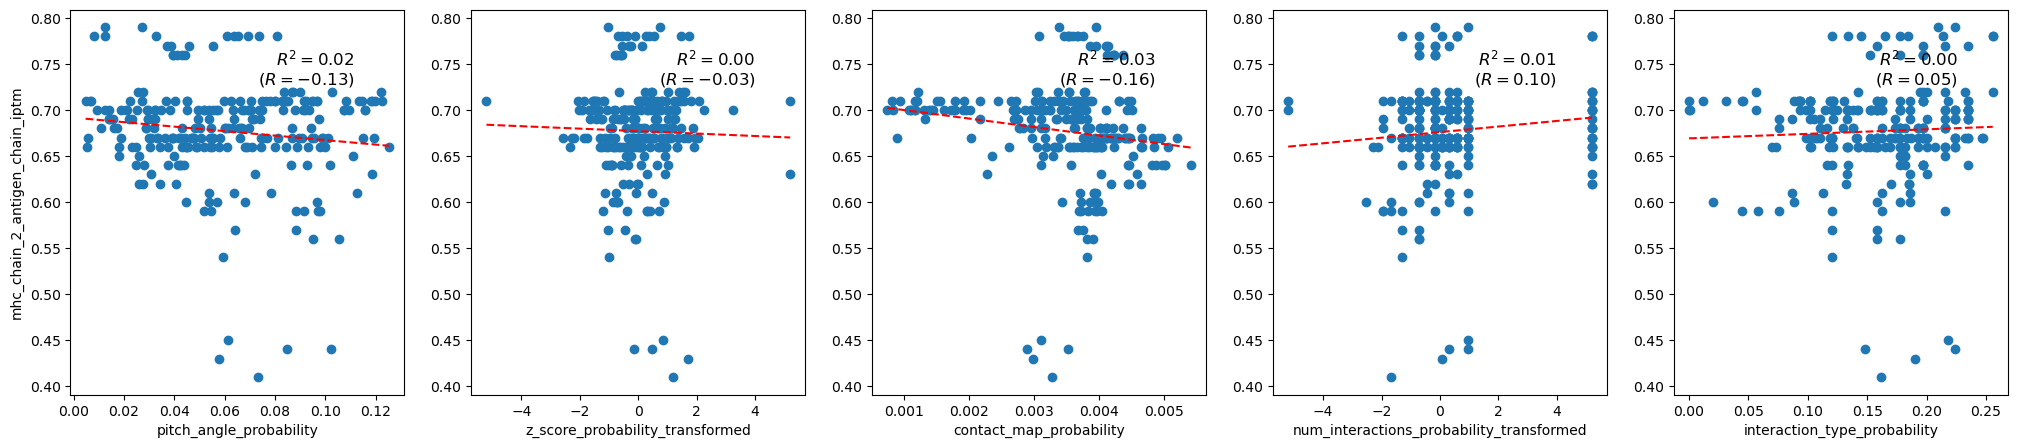

mhc_chain_2_beta_chain_iptm
Pearson's correlation: 0.36
                                 OLS Regression Results                                
Dep. Variable:     mhc_chain_2_beta_chain_iptm   R-squared:                       0.132
Model:                                     OLS   Adj. R-squared:                  0.114
Method:                          Least Squares   F-statistic:                     7.415
Date:                         Thu, 03 Jul 2025   Prob (F-statistic):           1.71e-06
Time:                                 12:11:37   Log-Likelihood:                 167.73
No. Observations:                          250   AIC:                            -323.5
Df Residuals:                              244   BIC:                            -302.3
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.713819,0.284478,2.509219,0.006374,True
z_score_probability_transformed,-0.010224,0.007543,-1.355449,0.911736,False
contact_map_probability,33.301496,8.730635,3.814327,0.000087,True
num_interactions_probability_transformed,-0.001074,0.004440,-0.241989,0.595504,False
interaction_type_probability,0.436872,0.160271,2.725826,0.003439,True


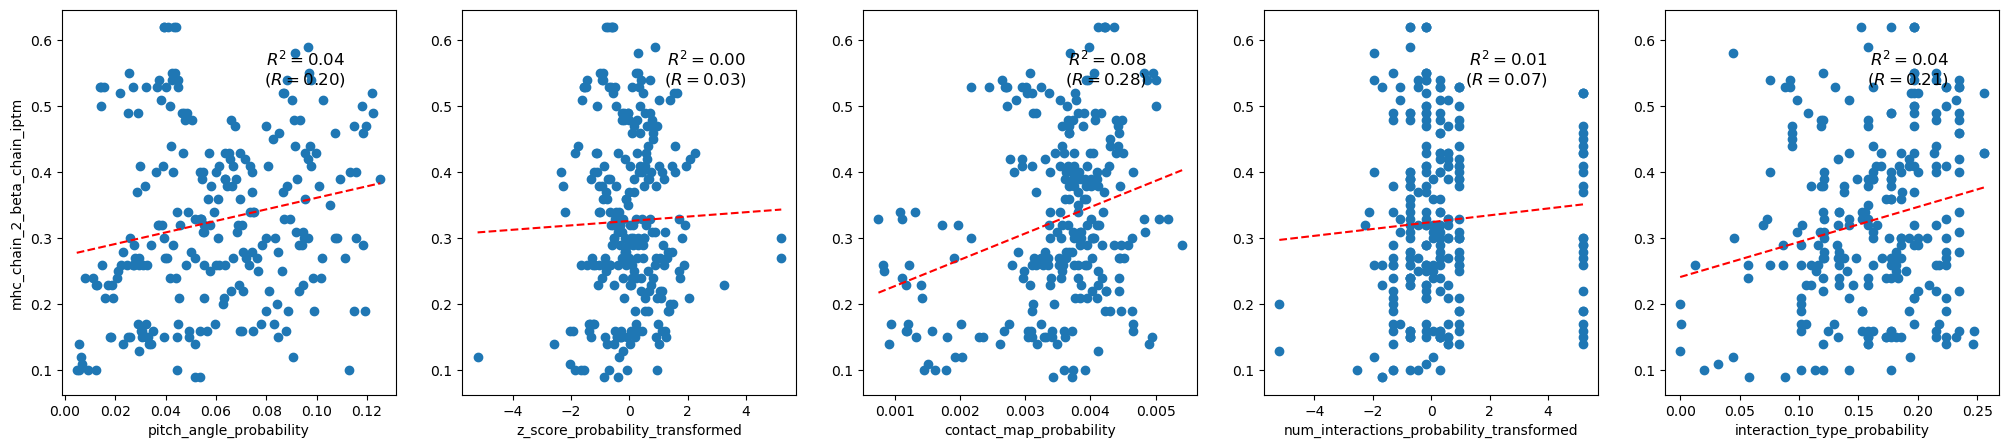

mhc_chain_2_iptm
Pearson's correlation: 0.31
                            OLS Regression Results                            
Dep. Variable:       mhc_chain_2_iptm   R-squared:                       0.098
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     5.323
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           0.000116
Time:                        12:11:38   Log-Likelihood:                 324.09
No. Observations:                 250   AIC:                            -636.2
Df Residuals:                     244   BIC:                            -615.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.265830,0.152203,1.746550,0.040987,True
z_score_probability_transformed,-0.005152,0.004036,-1.276616,0.898524,False
contact_map_probability,14.458987,4.671100,3.095414,0.001097,True
num_interactions_probability_transformed,0.000890,0.002375,0.374864,0.354044,False
interaction_type_probability,0.218939,0.085749,2.553247,0.005641,True


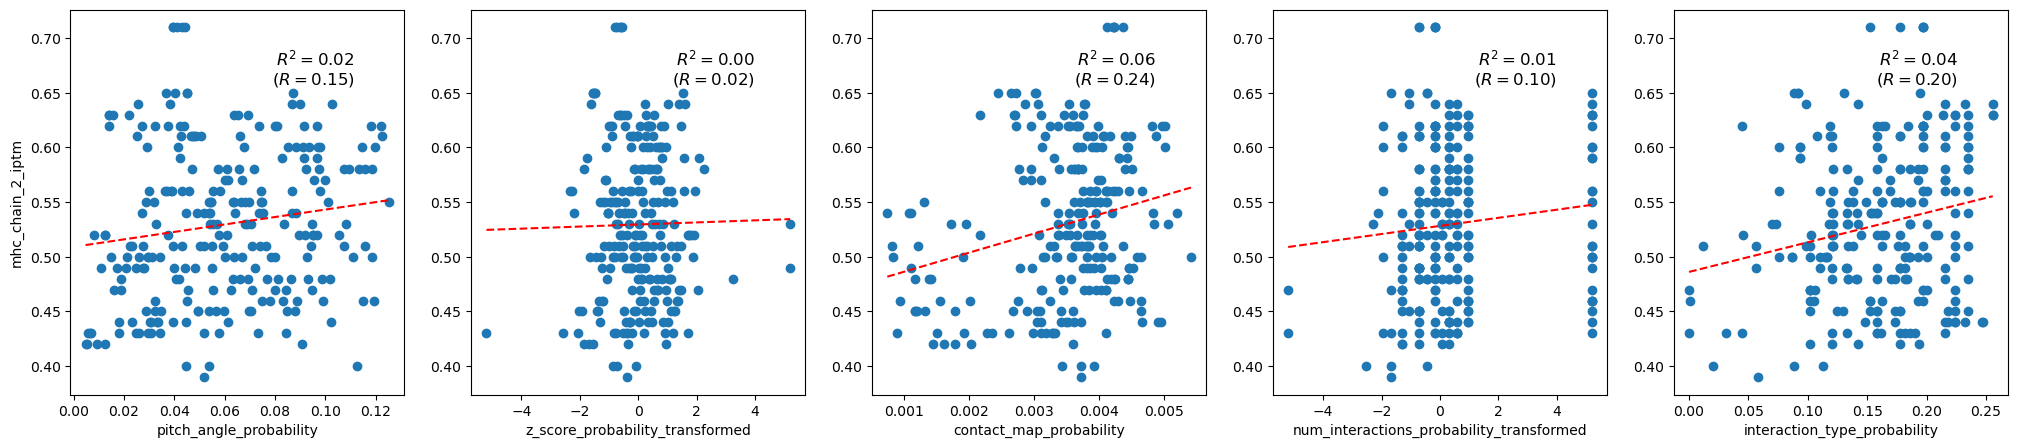

mhc_chain_2_ptm
Pearson's correlation: 0.29
                            OLS Regression Results                            
Dep. Variable:        mhc_chain_2_ptm   R-squared:                       0.082
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     4.347
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           0.000829
Time:                        12:11:39   Log-Likelihood:                 415.53
No. Observations:                 250   AIC:                            -819.1
Df Residuals:                     244   BIC:                            -797.9
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.253422,0.105581,-2.400258,0.991433,False
z_score_probability_transformed,-0.001249,0.002799,-0.446052,0.672023,False
contact_map_probability,5.909822,3.240284,1.823859,0.034698,True
num_interactions_probability_transformed,0.000955,0.001648,0.579729,0.281316,False
interaction_type_probability,0.185135,0.059483,3.112395,0.001038,True


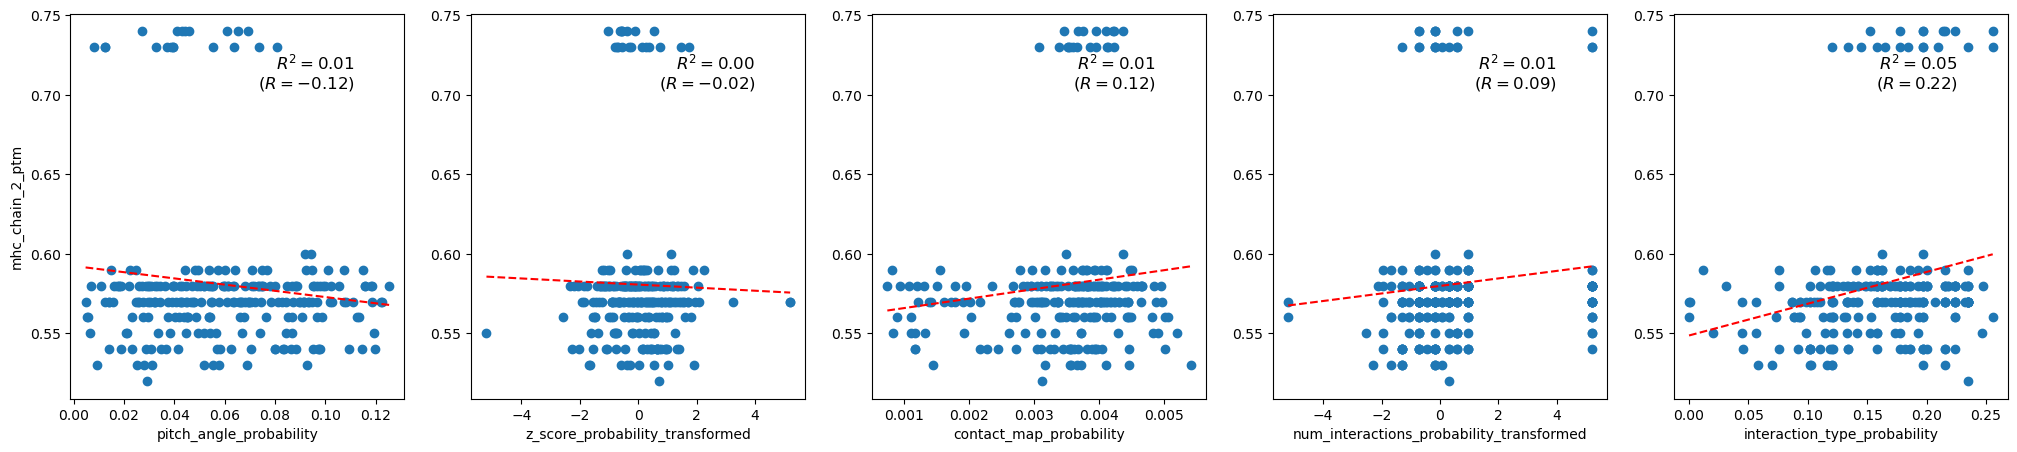

ptm
Pearson's correlation: 0.37
                            OLS Regression Results                            
Dep. Variable:                    ptm   R-squared:                       0.140
Model:                            OLS   Adj. R-squared:                  0.123
Method:                 Least Squares   F-statistic:                     7.964
Date:                Thu, 03 Jul 2025   Prob (F-statistic):           5.69e-07
Time:                        12:11:39   Log-Likelihood:                 324.18
No. Observations:                 250   AIC:                            -636.4
Df Residuals:                     244   BIC:                            -615.2
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.495743,0.152153,3.258183,0.000640,True
z_score_probability_transformed,-0.005686,0.004034,-1.409493,0.920019,False
contact_map_probability,17.947477,4.669580,3.843489,0.000077,True
num_interactions_probability_transformed,-0.000203,0.002375,-0.085341,0.533970,False
interaction_type_probability,0.187422,0.085721,2.186416,0.014868,True


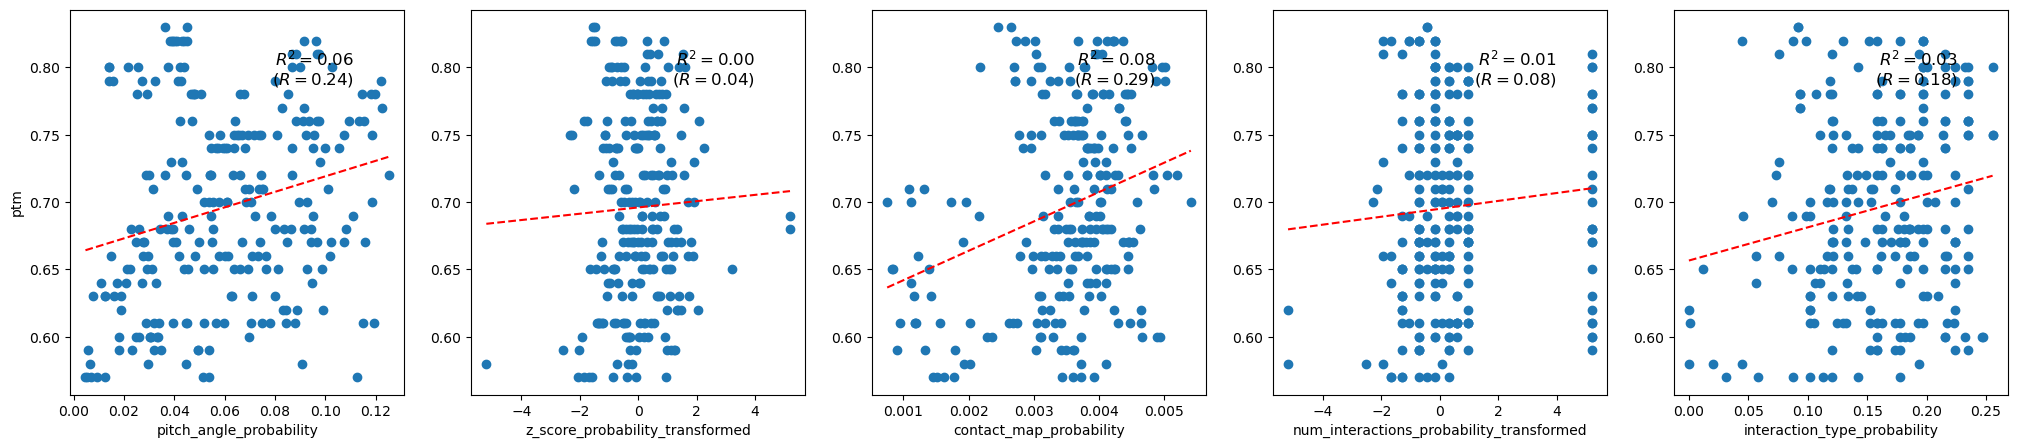

Best results: iptm R^2: 0.14537991675322504


In [40]:
ptm_confidence_columns = sorted(structure_scores.filter(regex='ptm').columns.tolist())

best_r_squared = 0
best_reg = None
best_name = None

X = structure_scores[structure_probability_names]
X = sm.add_constant(X)

for confidence_column in ptm_confidence_columns:
    y = structure_scores[confidence_column]

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    print(confidence_column)
    print('==============================================================================================')
    print(f"Pearson's correlation: {corr_coef:.2f}")
    print(reg.summary())
    print('\n\n')

    r_squared = reg.rsquared

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    display(coefficients)

    fig, axes = plt.subplots(1, len(structure_probability_names), figsize=(5 * len(structure_probability_names), 5))

    axes[0].set_ylabel(confidence_column)
    for i, column in enumerate(structure_probability_names):
        x = structure_scores[column]
        axes[i].plot(x, y, 'o')

        reg = scipy.stats.linregress(x, y)
        x = np.linspace(x.min(), x.max())
        y_pred = reg.slope * x + reg.intercept

        axes[i].plot(x, y_pred, 'r--')
        axes[i].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

        axes[i].set_xlabel(column)

    plt.show()

    if r_squared > best_r_squared:
        best_r_squared = r_squared
        best_reg = reg
        best_name = confidence_column


print('==============================================================================================')
print('Best results:', best_name, 'R^2:', best_r_squared)
print('==============================================================================================')